# 01 · El Stack de Data Science en Python
### NumPy · pandas · matplotlib/seaborn — la base de todo lo que viene

| | |
|---|---|
| **Archivo** | `01_python_ds_stack.ipynb` |
| **Base** | VanderPlas, *Python Data Science Handbook* (caps. 2, 3, 4) |
| **Versiones usadas** | Python 3.10+ · NumPy 2.x · pandas 2.x/3.x · matplotlib 3.x · seaborn 0.13 |

## Prerequisitos
Ninguno: es el punto de entrada. Basta saber Python básico (listas, diccionarios, funciones, `for`, `if`).

## Objetivos de aprendizaje
Al terminar podrás:
1. **Explicar y aplicar** vectorización y *broadcasting* en NumPy, y saber cuándo un `for` es un error de rendimiento.
2. **Transformar tablas** con pandas (`groupby`, `merge`, `pivot_table`, `.str`, `.dt`, categóricos, `pipe`) escribiendo cadenas legibles y sin mutaciones accidentales.
3. **Construir figuras** con la API orientada a objetos (`fig, ax`) y elegir el gráfico correcto entre los 6 fundamentales.
4. **Leer/escribir** CSV, JSON y Parquet entendiendo qué se pierde en cada formato, y hacer un EDA de 10 líneas.
5. **Reconocer los límites** del stack (todo en RAM) y qué herramienta usar cuando se superan.

## Mapa de conexiones

| Curso / evaluación | Qué parte de este notebook usas |
|---|---|
| **Big Data (CIT-2309)** | pandas es tu herramienta del proyecto ETL con MongoDB: lectura por *chunks*, limpieza, `groupby`, export a JSON (Ejercicio 3). Parquet ↔ almacenamiento columnar. |
| **IA (CIT-2013, AIMA)** | NumPy para implementar algoritmos desde cero: matrices de transición (cadenas de Markov, cap. 14 AIMA), distribuciones de probabilidad, distancias. |
| **Sistemas Distribuidos** | `.dt` y `.str` para logs y telemetría; `resample` para series de métricas; percentiles (p95) como en SLOs. |
| **Comunicaciones Digitales** | `np.linalg`, SVD, vectorización de señales (muestras como arrays). |
| **IA Avanzada (próximo semestre)** | Los tensores de TensorFlow/PyTorch **copian la API de NumPy**: broadcasting e indexación son idénticos. |

**Notebooks relacionados:** → `02_end_to_end_ml` (usa todo esto en un proyecto completo) · → `07_dimensionality_reduction` (SVD/eigen de la sección 3.5) · → `14_data_pipelines` (Parquet, ETL a escala).

## 1. Marco teórico

### 1.1 ¿Por qué existe NumPy? (intuición primero)

Una lista de Python guarda **punteros a objetos** dispersos en memoria; cada `float` es un objeto completo con cabecera, contador de referencias y tipo. Sumar dos listas elemento a elemento obliga al intérprete a comprobar tipos, desreferenciar y despachar **en cada iteración**.

Un `ndarray` guarda **valores crudos, contiguos y del mismo tipo**. Eso permite que un único bucle en C (con instrucciones SIMD y BLAS) recorra la memoria de corrido:

```
lista Python:   [ • ]──►[float obj]      ndarray float64:  [ 1.0 | 2.0 | 3.0 | 4.0 | ... ]
                [ • ]──►[float obj]                          ▲ un solo bloque contiguo, 8 bytes por valor
                [ • ]──►[float obj]                          ▲ el CPU lo lee en ráfagas (cache + SIMD)
```

> **Regla de oro:** si escribes un `for` sobre las filas de un array o DataFrame, casi siempre hay una operación vectorizada equivalente entre 10× y 1000× más rápida. El *por qué* no es magia: es el bucle interno el que cambia de Python a C.

### 1.2 Broadcasting: la regla

Para operar arrays de formas distintas, NumPy **alinea las formas por la derecha** y compara dimensión a dimensión. Dos dimensiones son compatibles si son **iguales** o **una de ellas es 1** (esa se "estira" virtualmente, sin copiar memoria).

```
 A      (500, 1, 3)               A      (3,)          B (2,1)... ✗
 B      ( 1, 40, 3)               B      (4,)    →  3 ≠ 4 y ninguna es 1 → ValueError
 ────────────────────
 A - B  (500, 40, 3)  ✓
```

Esto permite, por ejemplo, calcular **todas las distancias** entre dos conjuntos de puntos sin bucles (lo usarás en k-NN y K-Means, notebook 08).

### 1.3 Álgebra lineal que vas a necesitar

- Sistema lineal: $A\mathbf{x}=\mathbf{b}$ se resuelve con `np.linalg.solve` (nunca con $A^{-1}\mathbf{b}$: es más lento y numéricamente peor).
- Mínimos cuadrados (regresión lineal, notebook 04): $\hat{\theta}=(X^\top X)^{-1}X^\top y$, o mejor `np.linalg.lstsq`.
- Autovalores: $A\mathbf{v}=\lambda\mathbf{v}$. La distribución estacionaria $\pi$ de una cadena de Markov cumple $\pi P=\pi$, es decir, es autovector de $P^\top$ con $\lambda=1$ (AIMA cap. 14).
- SVD: $A=U\Sigma V^\top$. Truncando a los $k$ mayores valores singulares se obtiene la mejor aproximación de rango $k$ (teorema de Eckart–Young). Es la base de PCA (notebook 07).

### 1.4 pandas: el modelo mental

Un `DataFrame` es un **diccionario de columnas** (`Series`), cada una un array NumPy (o Arrow) con un `index` común. Casi todo se reduce a tres patrones:

| Patrón | Idea | Herramientas |
|---|---|---|
| **Split–Apply–Combine** | partir por clave, resumir cada grupo, recombinar | `groupby` + `agg` / `transform` |
| **Relacional** | unir tablas por clave (álgebra relacional de Bases de Datos) | `merge`, `concat` |
| **Reshape** | cambiar entre formato ancho y largo | `pivot_table`, `melt` |

Principio de *tidy data*: cada variable es una columna, cada observación una fila, cada tipo de unidad observacional una tabla.

> **Cambio importante en pandas 3.x:** *Copy-on-Write* es el comportamiento por defecto. Ya no existe el famoso `SettingWithCopyWarning`: un resultado derivado nunca modifica el original. Escribe siempre `df.loc[mask, "col"] = valor` o `df = df.assign(...)`, que funciona igual en todas las versiones. Además, las columnas de texto usan un dtype `str` dedicado en lugar de `object`.

### 1.5 matplotlib: anatomía de una figura

```
Figure  ── lienzo completo (tamaño, dpi)
 └─ Axes  ── un gráfico (el "ax" que usarás el 99% del tiempo)
     ├─ Axis (x, y) ── ejes con ticks y etiquetas
     ├─ Artists    ── líneas, puntos, barras, texto, leyenda
     └─ title / xlabel / ylabel / grid
```

Existen dos APIs: la de estado (`plt.plot(...)`, implícita y frágil) y la **orientada a objetos** (`fig, ax = plt.subplots()`; `ax.plot(...)`). Usa siempre la segunda: es explícita y escala a figuras con varios paneles.

### 1.6 Limitación honesta del stack
Todo vive **en RAM de una sola máquina** y pandas es mayormente *single-thread*. Regla práctica: pandas cómodo hasta ~1/5 de tu RAM. Más allá: **Polars** o **DuckDB** (una máquina, mucho más rápidos y eficientes en memoria), **Dask** o **Spark** (clúster; lo verás en Big Data). La *API* cambia, los conceptos (groupby, merge, columnar) son los mismos.

## 2. Configuración

In [1]:
# --- Biblioteca estándar ---
import os
import time
import json
import tempfile
import warnings
from pathlib import Path

# --- Datos ---
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist   # solo para VERIFICAR nuestro broadcasting

# --- ML (aquí solo para cargar el dataset) ---
from sklearn.datasets import fetch_california_housing

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# macOS + Python de python.org a veces no encuentra certificados SSL;
# certifi trae un bundle fiable y evita desactivar la verificación.
try:
    import certifi
    os.environ.setdefault("SSL_CERT_FILE", certifi.where())
except ImportError:
    pass

# --- Reproducibilidad ---
SEED = 42
np.random.seed(SEED)               # para código legado que use np.random.*
rng = np.random.default_rng(SEED)  # API moderna: pásala explícitamente a las funciones

# --- Gráficos en alta resolución ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (7, 4),
    "axes.titlesize": 12, "axes.labelsize": 10, "grid.alpha": 0.35,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# Los FutureWarning de librerías en transición confunden más de lo que ayudan en un tutorial
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"NumPy {np.__version__} | pandas {pd.__version__} | matplotlib {plt.matplotlib.__version__} | seaborn {sns.__version__}")

NumPy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
# ---------- Helpers reutilizables ----------

def time_ms(fn, *args, repeat=5):
    # Tomamos el MÍNIMO de varias corridas: el ruido del SO solo suma tiempo, nunca lo resta
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter()
        fn(*args)
        best = min(best, time.perf_counter() - t0)
    return best * 1e3


def load_housing() -> pd.DataFrame:
    # as_frame=True devuelve un DataFrame con el target (MedHouseVal) incluido
    return fetch_california_housing(as_frame=True).frame


def quick_eda(df: pd.DataFrame, target: str | None = None, top_corr: int = 5) -> None:
    # EDA en ~10 líneas: forma, memoria, duplicados, tipos, nulos, resumen y correlaciones
    mem = df.memory_usage(deep=True).sum() / 1e6
    print(f"shape={df.shape} | memoria={mem:.2f} MB | filas duplicadas={df.duplicated().sum()}")
    summary = pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls_%": df.isna().mean() * 100,
                            "unique": df.nunique()})
    stats = df.select_dtypes("number").describe().T[["mean", "std", "min", "50%", "max"]]
    display(summary.join(stats))
    if target is not None:
        corr = df.select_dtypes("number").corr()[target].drop(target)
        display(corr.sort_values(key=abs, ascending=False).head(top_corr).to_frame("corr con " + target))


def savefig_tmp(fig, name: str) -> Path:
    # Guardar a un directorio temporal para no ensuciar el proyecto
    path = Path(tempfile.gettempdir()) / name
    fig.savefig(path, bbox_inches="tight")
    return path

## 3. NumPy esencial

### 3.1 El ndarray: forma, tipo y memoria
Tres atributos explican casi todo el comportamiento de un array: `shape`, `dtype` y `strides`. Elegir `float32` en vez de `float64` **divide la memoria por 2**, algo decisivo en deep learning (la GPU trabaja en `float32`/`float16`).

In [3]:
a = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float64)
print("shape  :", a.shape, "| ndim:", a.ndim, "| size:", a.size)
print("dtype  :", a.dtype, "| bytes totales:", a.nbytes, "| strides (bytes por paso):", a.strides)

# float32 vs float64: misma información útil para ML, mitad de memoria
big64 = np.zeros((1000, 1000), dtype=np.float64)
big32 = big64.astype(np.float32)
print(f"\n1000x1000 float64 = {big64.nbytes/1e6:.1f} MB | float32 = {big32.nbytes/1e6:.1f} MB")

# Vista vs copia: el slicing NO copia (devuelve una vista sobre la misma memoria)
col = a[:, 0]
col[0] = 99
print("\nTras modificar la vista, el original cambió:\n", a)
print("¿comparten memoria?", np.shares_memory(a, col), "| con .copy():", np.shares_memory(a, a[:, 0].copy()))

shape  : (2, 3) | ndim: 2 | size: 6
dtype  : float64 | bytes totales: 48 | strides (bytes por paso): (24, 8)

1000x1000 float64 = 8.0 MB | float32 = 4.0 MB

Tras modificar la vista, el original cambió:
 [[99.  2.  3.]
 [ 4.  5.  6.]]
¿comparten memoria? True | con .copy(): False


> **Trampa clásica:** el *slicing* devuelve **vistas**; el *fancy indexing* (con listas/máscaras) devuelve **copias**. Si modificas una vista, modificas el original. Ante la duda, `.copy()`.

### 3.2 Vectorización vs bucles
Midamos el costo real de un bucle de Python frente a la operación vectorizada: suma de cuadrados de un millón de números.

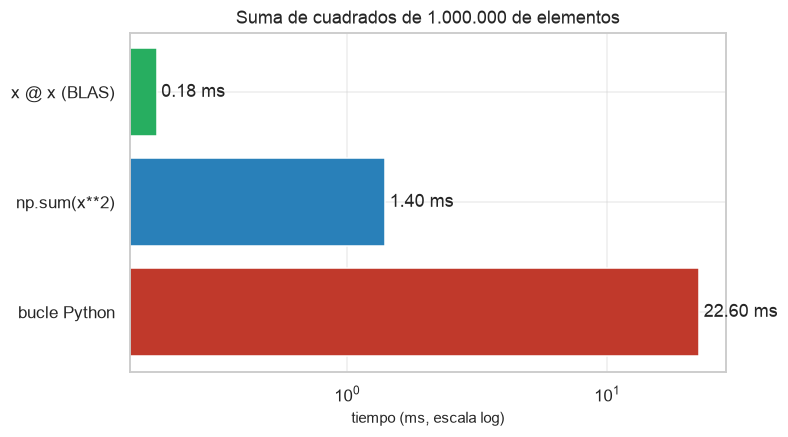

Speedup vectorizado vs bucle: 122x


In [4]:
x = rng.normal(size=1_000_000)
x_list = x.tolist()   # el MEJOR caso para el bucle: lista nativa de Python (iterar el ndarray es aún más lento)

def sumsq_loop(v):
    s = 0.0
    for t in v:
        s += t * t
    return s

def sumsq_vec(v):
    return float(v @ v)          # producto punto: BLAS, un único bucle en C

def sumsq_sum(v):
    return float(np.sum(v ** 2))  # crea un temporal de 8 MB, pero igual es vectorizado

assert np.isclose(sumsq_loop(x_list), sumsq_vec(x)) and np.isclose(sumsq_vec(x), sumsq_sum(x))

times = {
    "bucle Python": time_ms(sumsq_loop, x_list, repeat=3),
    "np.sum(x**2)": time_ms(sumsq_sum, x),
    "x @ x (BLAS)": time_ms(sumsq_vec, x),
}
fig, ax = plt.subplots()
bars = ax.barh(list(times), list(times.values()), color=["#c0392b", "#2980b9", "#27ae60"])
ax.set(xscale="log", xlabel="tiempo (ms, escala log)", title="Suma de cuadrados de 1.000.000 de elementos")
ax.bar_label(bars, fmt="%.2f ms", padding=3)
ax.grid(True, axis="x")
plt.show()
print(f"Speedup vectorizado vs bucle: {times['bucle Python'] / times['x @ x (BLAS)']:.0f}x")

### 3.3 Broadcasting en acción
Tres usos que verás constantemente:
1. **Estandarizar columnas:** `(X - mu) / sigma` con `mu` de forma `(d,)` sobre `X` de forma `(n, d)`.
2. **Tablas de operaciones** (fila × columna) con formas `(n, 1)` y `(1, m)`.
3. **Distancias por pares** insertando ejes con `None` / `np.newaxis`.

In [5]:
# 1) Estandarizar columnas: (n, d) - (d,)  → la media se "estira" sobre las n filas
X = rng.normal(loc=[10, 100, 1000], scale=[1, 10, 100], size=(5000, 3))
X_std = (X - X.mean(axis=0)) / X.std(axis=0)
print("medias tras estandarizar:", X_std.mean(axis=0).round(6), "| desv.:", X_std.std(axis=0).round(6))

# 2) Fila × columna: (4, 1) * (1, 5) → (4, 5)
print("\nTabla de multiplicar:\n", np.arange(1, 5)[:, None] * np.arange(1, 6)[None, :])

# 3) Distancias euclídeas por pares SIN bucles: (500,1,3) - (1,40,3) → (500,40,3) → suma sobre el último eje
A = rng.normal(size=(500, 3))
B = rng.normal(size=(40, 3))
D = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=-1))
assert np.allclose(D, cdist(A, B))   # coincide con la implementación de SciPy
print("\nMatriz de distancias:", D.shape, "| vecino más cercano de A[0] es B[%d]" % D[0].argmin())

# Error típico: formas incompatibles. Leer el mensaje es la mitad de la depuración
try:
    np.ones((3,)) + np.ones((4,))
except ValueError as e:
    print("\nValueError:", e)

medias tras estandarizar: [0. 0. 0.] | desv.: [1. 1. 1.]

Tabla de multiplicar:
 [[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]]

Matriz de distancias: (500, 40) | vecino más cercano de A[0] es B[7]

ValueError: operands could not be broadcast together with shapes (3,) (4,) 


> **Memoria:** el truco `(500,1,3) - (1,40,3)` materializa un temporal `(500,40,3)`. Para millones de puntos usa `cdist` (no crea el temporal 3D) o procesa por bloques.

### 3.4 Indexación avanzada

In [6]:
Mx = np.arange(20).reshape(4, 5)
print(Mx, "\n")

print("slicing   Mx[1:3, ::2]     :\n", Mx[1:3, ::2])
print("máscara   Mx[Mx % 7 == 0]  :", Mx[Mx % 7 == 0])
print("fancy     Mx[[0, 3], [1, 4]] (pares (0,1) y (3,4)):", Mx[[0, 3], [1, 4]])
print("np.ix_    submatriz filas {0,3} × cols {1,4}:\n", Mx[np.ix_([0, 3], [1, 4])])

# np.where: if/else vectorizado (ej. recortar valores negativos como un ReLU)
z = np.array([-2.0, -0.5, 0.0, 1.5, 3.0])
print("\nReLU con np.where:", np.where(z > 0, z, 0.0), "| equivalente: np.maximum(z, 0) =", np.maximum(z, 0))

# top-k sin ordenar todo: argpartition es O(n) en vez de O(n log n)
scores = rng.random(1_000)
k = 5
top_k = np.argpartition(scores, -k)[-k:]
top_k = top_k[np.argsort(scores[top_k])[::-1]]
print(f"\nTop-{k} índices:", top_k, "| valores:", scores[top_k].round(3))

[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]] 

slicing   Mx[1:3, ::2]     :
 [[ 5  7  9]
 [10 12 14]]
máscara   Mx[Mx % 7 == 0]  : [ 0  7 14]
fancy     Mx[[0, 3], [1, 4]] (pares (0,1) y (3,4)): [ 1 19]
np.ix_    submatriz filas {0,3} × cols {1,4}:
 [[ 1  4]
 [16 19]]

ReLU con np.where: [0.  0.  0.  1.5 3. ] | equivalente: np.maximum(z, 0) = [0.  0.  0.  1.5 3. ]

Top-5 índices: [307 827 539 534 909] | valores: [0.999 0.999 0.998 0.998 0.998]


### 3.5 Álgebra lineal con `np.linalg`
Cuatro operaciones que sostienen medio curso de IA: resolver sistemas, mínimos cuadrados, autovalores (Markov) y SVD.

In [7]:
# --- (a) Resolver A x = b: solve > inv ---
A_ = np.array([[3.0, 1.0], [1.0, 2.0]])
b_ = np.array([9.0, 8.0])
x_ = np.linalg.solve(A_, b_)
print("solución x =", x_, "| residuo ||Ax-b|| =", np.linalg.norm(A_ @ x_ - b_))
print("número de condición de A:", round(np.linalg.cond(A_), 2), "(>1e10 = sistema mal condicionado)")

# --- (b) Mínimos cuadrados: y = 3 + 2x + ruido (adelanto del notebook 04) ---
n = 200
feat = rng.uniform(0, 10, n)
y_ = 3 + 2 * feat + rng.normal(0, 1, n)
X_design = np.column_stack([np.ones(n), feat])           # columna de 1s = intercepto
theta_normal = np.linalg.solve(X_design.T @ X_design, X_design.T @ y_)   # ecuación normal
theta_lstsq, *_ = np.linalg.lstsq(X_design, y_, rcond=None)              # más estable (usa SVD)
print("\nθ (ecuación normal):", theta_normal.round(3), "| θ (lstsq):", theta_lstsq.round(3), "| real: [3, 2]")

solución x = [2. 3.] | residuo ||Ax-b|| = 0.0
número de condición de A: 2.62 (>1e10 = sistema mal condicionado)

θ (ecuación normal): [2.892 2.02 ] | θ (lstsq): [2.892 2.02 ] | real: [3, 2]


In [8]:
# --- (c) Cadena de Markov del clima (AIMA cap. 14): distribución estacionaria ---
states = ["Soleado", "Nublado", "Lluvioso"]
P = np.array([[0.7, 0.2, 0.1],
              [0.3, 0.4, 0.3],
              [0.2, 0.3, 0.5]])          # P[i, j] = P(mañana=j | hoy=i); cada fila suma 1
assert np.allclose(P.sum(axis=1), 1)

# π P = π  ⇔  Pᵀ π = π: autovector de Pᵀ con autovalor 1
eigvals, eigvecs = np.linalg.eig(P.T)
idx = np.argmin(np.abs(eigvals - 1))
pi = np.real(eigvecs[:, idx])
pi = pi / pi.sum()                       # normalizar para que sea distribución de probabilidad

print("Estacionaria vía autovectores :", {s_: round(float(v), 4) for s_, v in zip(states, pi)})
print("Estacionaria vía P^50 (fila 0):", {s_: round(float(v), 4) for s_, v in zip(states, np.linalg.matrix_power(P, 50)[0])})
assert np.allclose(pi @ P, pi)

Estacionaria vía autovectores : {'Soleado': 0.4565, 'Nublado': 0.2826, 'Lluvioso': 0.2609}
Estacionaria vía P^50 (fila 0): {'Soleado': 0.4565, 'Nublado': 0.2826, 'Lluvioso': 0.2609}


{1: '77.306%', 2: '52.032%', 3: '5.977%', 5: '5.638%', 10: '4.857%'}


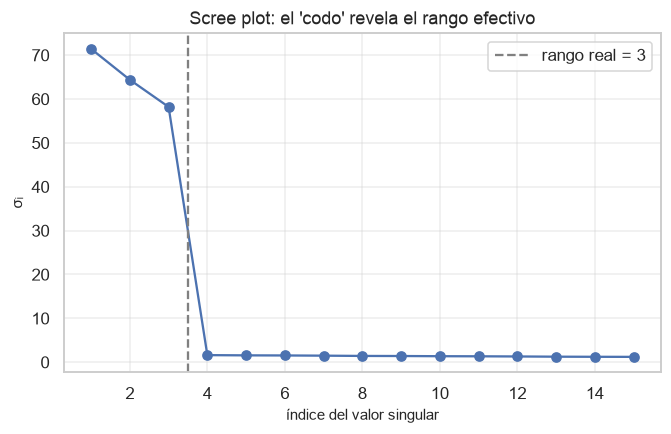

In [9]:
# --- (d) SVD y aproximación de bajo rango (base de PCA, notebook 07) ---
# Matriz 100x50 de rango real 3 + ruido: la SVD debe "descubrir" que hay 3 direcciones relevantes
latent = rng.normal(size=(100, 3)) @ rng.normal(size=(3, 50))
M_noisy = latent + 0.1 * rng.normal(size=(100, 50))

U, s, Vt = np.linalg.svd(M_noisy, full_matrices=False)

def rank_k(U, s, Vt, k):
    return (U[:, :k] * s[:k]) @ Vt[:k]     # U_k Σ_k V_kᵀ

errors = {k: np.linalg.norm(M_noisy - rank_k(U, s, Vt, k)) / np.linalg.norm(M_noisy) for k in (1, 2, 3, 5, 10)}
print({k: f"{e:.3%}" for k, e in errors.items()})

fig, ax = plt.subplots()
ax.plot(range(1, 16), s[:15], "o-")
ax.axvline(3.5, ls="--", color="gray", label="rango real = 3")
ax.set(xlabel="índice del valor singular", ylabel="σᵢ", title="Scree plot: el 'codo' revela el rango efectivo")
ax.legend()
plt.show()

## 4. pandas intermedio

### 4.1 Cargar y mirar: California Housing
Dataset del censo de California de 1990 (Géron lo usa en el cap. 2). Cada fila es un **distrito censal**, no una casa. Variables: ingreso mediano (`MedInc`, en decenas de miles de USD), antigüedad (`HouseAge`), promedios de habitaciones/dormitorios/ocupantes **por hogar**, `Population`, coordenadas, y el target `MedHouseVal` (valor mediano en cientos de miles de USD, **truncado en 5.0**).

In [10]:
df = load_housing()
df.info()
display(df.head())
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


### 4.2 Tipos categóricos y discretización
`pd.cut` (rangos fijos) y `pd.qcut` (cuantiles) convierten numéricas en categorías. El dtype `category` ahorra memoria y fija un **orden** semántico.

In [11]:
income_labels = ["bajo", "medio-bajo", "medio", "medio-alto", "alto"]
df["income_cat"] = pd.cut(df["MedInc"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=income_labels, ordered=True)
df["age_cat"] = pd.qcut(df["HouseAge"], q=3, labels=["nuevo", "medio", "antiguo"])   # terciles: grupos de igual tamaño

print("dtype:", df["income_cat"].dtype)
print(df["income_cat"].value_counts(sort=False))

# Ahorro de memoria: categoría (códigos enteros + diccionario) vs. texto repetido
as_text = df["income_cat"].astype(str)
print(f"\nMemoria como texto: {as_text.memory_usage(deep=True)/1e6:.2f} MB | como category: {df['income_cat'].memory_usage(deep=True)/1e6:.2f} MB")

dtype: category
income_cat
bajo           822
medio-bajo    6581
medio         7236
medio-alto    3639
alto          2362
Name: count, dtype: int64

Memoria como texto: 0.32 MB | como category: 0.02 MB


### 4.3 Valores nulos
Primero **mide** (cuántos y dónde), luego **decide**: eliminar, imputar o marcar. Imputar con la mediana *del grupo* suele ser mejor que con la mediana global. California Housing no trae nulos, así que los inyectamos en una copia para practicar.

In [12]:
df_na = df.copy()
mask = rng.random(len(df_na)) < 0.05
df_na.loc[mask, "AveRooms"] = np.nan          # .loc con máscara: la forma segura de asignar

print(f"nulos en AveRooms: {df_na['AveRooms'].isna().sum()} ({df_na['AveRooms'].isna().mean():.1%})")

# (a) Imputación global vs (b) por grupo: la estructura de los datos se respeta mejor con (b)
global_med = df_na["AveRooms"].fillna(df_na["AveRooms"].median())
group_med = df_na["AveRooms"].fillna(df_na.groupby("income_cat", observed=True)["AveRooms"].transform("median"))

# Evaluamos contra el valor REAL que ocultamos (algo que solo podemos hacer porque inyectamos el nulo)
true = df.loc[mask, "AveRooms"]
for name, imputed in [("global", global_med), ("por grupo", group_med)]:
    mae = (imputed[mask] - true).abs().mean()
    print(f"MAE imputación {name:10s}: {mae:.3f}")

# (c) Indicador de "faltaba": a veces la ausencia ES información (útil para modelos)
df_na["AveRooms_missing"] = df_na["AveRooms"].isna().astype("int8")

nulos en AveRooms: 1046 (5.1%)
MAE imputación global    : 1.084
MAE imputación por grupo : 0.811


### 4.4 `groupby`: split – apply – combine
- `.agg(...)`: **reduce** cada grupo a una fila (resúmenes).
- `.transform(...)`: devuelve algo **del mismo tamaño** que el original (ideal para features "relativas al grupo").
- Usa *named aggregation* (`nombre=("columna", "función")`) para columnas de salida claras.

In [13]:
stats = (df.groupby("income_cat", observed=True)
           .agg(n=("MedHouseVal", "size"),
                precio_medio=("MedHouseVal", "mean"),
                precio_mediana=("MedHouseVal", "median"),
                precio_std=("MedHouseVal", "std"),
                edad_media=("HouseAge", "mean")))
display(stats)

# transform: cuánto se desvía cada distrito del promedio de SU grupo de ingreso (misma longitud que df)
df["val_vs_group"] = df["MedHouseVal"] - df.groupby("income_cat", observed=True)["MedHouseVal"].transform("mean")
print("media de val_vs_group por grupo (debe ser ~0):", df.groupby("income_cat", observed=True)["val_vs_group"].mean().abs().max().round(10))

,n,precio_medio,precio_mediana,precio_std,edad_media
income_cat,,,,,
bajo,822,1.121,0.895,0.790,32.189
medio-bajo,6581,1.365,1.192,0.730,30.353
medio,7236,1.996,1.804,0.907,28.874
medio-alto,3639,2.583,2.399,0.924,26.262
alto,2362,3.787,3.718,1.018,25.574


media de val_vs_group por grupo (debe ser ~0): 0.0


### 4.5 `merge`: unir tablas
Es un JOIN de SQL (lo mismo que en Bases de Datos). Entiende primero la diferencia entre tipos de unión con tablas minúsculas.

In [14]:
left = pd.DataFrame({"key": [1, 2, 3], "x": ["a", "b", "c"]})
right = pd.DataFrame({"key": [2, 3, 4], "y": ["B", "C", "D"]})

for how in ["inner", "left", "right", "outer"]:
    print(f"--- how='{how}' ---")
    print(left.merge(right, on="key", how=how).to_string(index=False))

--- how='inner' ---
 key x y
   2 b B
   3 c C
--- how='left' ---
 key x   y
   1 a NaN
   2 b   B
   3 c   C
--- how='right' ---
 key   x y
   2   b B
   3   c C
   4 NaN D
--- how='outer' ---
 key   x   y
   1   a NaN
   2   b   B
   3   c   C
   4 NaN   D


Aplicación real: asignamos cada distrito a la **ciudad grande más cercana** (broadcasting de la sección 3.3) y luego enriquecemos con una tabla de metadatos mediante `merge`. `validate="m:1"` hace fallar el código si la clave de la derecha no fuera única: protege de duplicar filas silenciosamente.

> Limitación: usamos distancia euclídea sobre grados lat/lon. Es una aproximación aceptable a esta escala; para distancias reales usa la fórmula de *haversine*.

In [15]:
cities = pd.DataFrame({
    "city": ["Los Angeles", "San Francisco", "San Diego", "Sacramento", "San Jose"],
    "lat": [34.05, 37.77, 32.72, 38.58, 37.34],
    "lon": [-118.24, -122.42, -117.16, -121.49, -121.89],
})
city_info = pd.DataFrame({"city": cities["city"], "region": ["Sur", "Bahía", "Sur", "Valle Central", "Bahía"]})

# (n_distritos, 2) vs (n_ciudades, 2) → (n_distritos, n_ciudades) sin bucles
dist = cdist(df[["Latitude", "Longitude"]].to_numpy(), cities[["lat", "lon"]].to_numpy())
df["city"] = cities["city"].to_numpy()[dist.argmin(axis=1)]

df = df.merge(city_info, on="city", how="left", validate="m:1")
assert df["region"].notna().all()      # un left join sin match dejaría NaN: lo verificamos explícitamente

display(df.groupby(["region", "city"], observed=True)["MedHouseVal"].agg(["count", "mean"]).round(3))

count   mean
region        city                       
Bahía         San Francisco   3091  2.465
              San Jose        3077  2.118
Sur           Los Angeles     9852  2.210
              San Diego       2083  1.798
Valle Central Sacramento      2537  1.197

### 4.6 `pivot_table` y `melt`: ancho ↔ largo
`pivot_table` = tabla dinámica de Excel (con agregación). `melt` hace lo inverso: de ancho a largo, el formato que prefieren seaborn y los modelos.

In [16]:
pivot = df.pivot_table(index="income_cat", columns="age_cat", values="MedHouseVal", aggfunc="mean", observed=True)
display(pivot.round(3))

# De vuelta a formato largo (tidy)
long = pivot.reset_index().melt(id_vars="income_cat", var_name="age_cat", value_name="precio_medio")
display(long.head(6))

age_cat,nuevo,medio,antiguo
income_cat,,,
bajo,1.216,1.043,1.121
medio-bajo,1.257,1.366,1.456
medio,1.738,1.972,2.301
medio-alto,2.284,2.612,3.053
alto,3.399,3.899,4.388


,income_cat,age_cat,precio_medio
0,bajo,nuevo,1.216
1,medio-bajo,nuevo,1.257
2,medio,nuevo,1.738
3,medio-alto,nuevo,2.284
4,alto,nuevo,3.399
5,bajo,medio,1.043


### 4.7 Logs: `.dt` (fechas) y `.str` (texto)
Escenario de **Sistemas Distribuidos**: logs de servicios con timestamp, latencia y mensaje. Los accesores `.dt` y `.str` aplican operaciones vectorizadas a columnas completas (no uses `apply` con `lambda` si existe un método `.str`/`.dt`).

In [17]:
n_logs = 3000
messages = ["GET /users/17 200", "POST /login 401", "GET /items/52 200", "POST /orders 500",
            "GET /health 200", "timeout connecting to db-02"]
logs = pd.DataFrame({
    "timestamp": pd.date_range("2026-01-01", periods=n_logs, freq="7min"),
    "service": rng.choice(["auth", "api", "db", "cache"], n_logs),
    "level": rng.choice(["INFO", "WARN", "ERROR"], n_logs, p=[0.80, 0.15, 0.05]),
    "latency_ms": rng.lognormal(mean=4.0, sigma=0.6, size=n_logs).round(1),
    "msg": rng.choice(messages, n_logs),
})

# --- .dt: componentes temporales ---
logs["hour"] = logs["timestamp"].dt.hour
logs["weekday"] = logs["timestamp"].dt.day_name()

# --- .str: extraer campos con regex de grupos nombrados; lo que no calza queda NaN ---
parsed = logs["msg"].str.extract(r"(?P<method>GET|POST)\s+(?P<path>\S+)\s+(?P<status>\d{3})")
logs = logs.join(parsed)
logs["status"] = pd.to_numeric(logs["status"], errors="coerce").astype("Int16")   # Int16 (con I mayúscula) admite NA
logs["is_timeout"] = logs["msg"].str.contains("timeout", case=False)

display(logs.head())
print("filas sin método HTTP (mensajes no parseables):", logs["method"].isna().sum())

# Percentiles: en SLOs importa la cola (p95/p99), no el promedio
print("\nlatencia por servicio (ms):")
display(logs.groupby("service")["latency_ms"].agg(mean="mean", p95=lambda s: s.quantile(0.95)).round(1))

# resample: agrupar por ventana de tiempo (requiere índice temporal)
hourly = logs.set_index("timestamp")["latency_ms"].resample("6h").agg(["mean", "max"])
display(hourly.head())

,timestamp,service,level,latency_ms,msg,hour,weekday,method,path,status,is_timeout
0,2026-01-01 00:00:00,cache,INFO,38.8,GET /users/17 200,0,Thursday,GET,/users/17,200,False
1,2026-01-01 00:07:00,db,INFO,55.0,POST /login 401,0,Thursday,POST,/login,401,False
2,2026-01-01 00:14:00,cache,INFO,58.5,POST /orders 500,0,Thursday,POST,/orders,500,False
3,2026-01-01 00:21:00,db,INFO,40.0,GET /users/17 200,0,Thursday,GET,/users/17,200,False
4,2026-01-01 00:28:00,api,INFO,284.4,POST /login 401,0,Thursday,POST,/login,401,False


filas sin método HTTP (mensajes no parseables): 486

latencia por servicio (ms):


,mean,p95
service,,
api,62.8,146.5
auth,65.2,151.7
cache,68.8,164.3
db,67.4,151.0


,mean,max
timestamp,,
2026-01-01 00:00:00,60.883,284.4
2026-01-01 06:00:00,63.976,187.3
2026-01-01 12:00:00,66.158,197.2
2026-01-01 18:00:00,73.435,299.6
2026-01-02 00:00:00,65.712,309.3


### 4.8 Encadenamiento y `pipe`
Una cadena de métodos se lee de arriba abajo como una receta, no deja variables intermedias y **evita mutar** el original. `pipe` permite insertar tus propias funciones en la cadena (patrón que reaparece en `sklearn.Pipeline`, notebook 02).

In [18]:
def add_features(d: pd.DataFrame) -> pd.DataFrame:
    return d.assign(rooms_per_person=d["AveRooms"] / d["AveOccup"],
                    bedroom_ratio=d["AveBedrms"] / d["AveRooms"])

def drop_outliers(d: pd.DataFrame, col: str, upper_q: float = 0.999) -> pd.DataFrame:
    return d[d[col] <= d[col].quantile(upper_q)]

summary = (
    df
    .pipe(drop_outliers, col="AveOccup")            # ocupación absurda = probable dato erróneo/institución
    .pipe(add_features)
    .query("Population > 100")
    .groupby("region", observed=True)
    .agg(n=("MedHouseVal", "size"),
         precio=("MedHouseVal", "mean"),
         hab_por_persona=("rooms_per_person", "mean"))
    .round(3)
    .sort_values("precio", ascending=False)
)
display(summary)

,n,precio,hab_por_persona
region,,,
Bahía,6086,2.292,2.023
Sur,11816,2.141,1.851
Valle Central,2481,1.194,2.285


## 5. matplotlib + seaborn

### 5.1 Anatomía de una figura (API orientada a objetos)
`fig` es el lienzo; `ax` es donde dibujas. Todo se configura sobre `ax` (`ax.set(...)`, `ax.legend()`), no con funciones globales de `plt`.

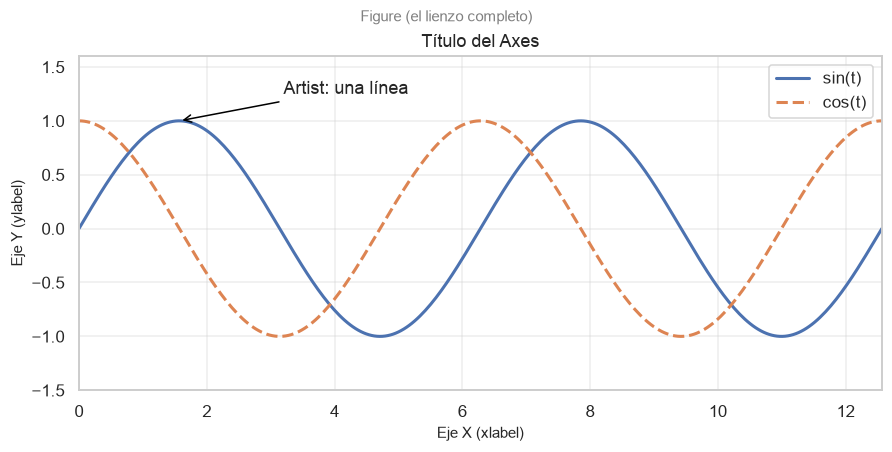

In [19]:
t = np.linspace(0, 4 * np.pi, 300)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")     # constrained: evita que se superpongan etiquetas
ax.plot(t, np.sin(t), label="sin(t)", lw=2)
ax.plot(t, np.cos(t), label="cos(t)", lw=2, ls="--")
ax.set(title="Título del Axes", xlabel="Eje X (xlabel)", ylabel="Eje Y (ylabel)", xlim=(0, 4 * np.pi))
ax.legend(loc="upper right")
ax.annotate("Artist: una línea", xy=(np.pi / 2, 1), xytext=(3.2, 1.25), arrowprops=dict(arrowstyle="->", color="black"))
ax.set_ylim(-1.5, 1.6)
fig.suptitle("Figure (el lienzo completo)", fontsize=10, color="gray")
plt.show()

### 5.2 Los 6 gráficos que más vas a usar

| Pregunta | Gráfico |
|---|---|
| ¿Cómo evoluciona en el tiempo / en orden? | **línea** |
| ¿Cómo se relacionan dos variables numéricas? | **scatter** |
| ¿Cómo se distribuye una variable? | **histograma** |
| ¿Cómo se comparan categorías (un valor por categoría)? | **barras** |
| ¿Cómo se relacionan *muchas* variables a la vez? | **heatmap** (típicamente de correlaciones) |
| ¿Cómo se distribuye una variable *dentro de* cada categoría? | **boxplot** |

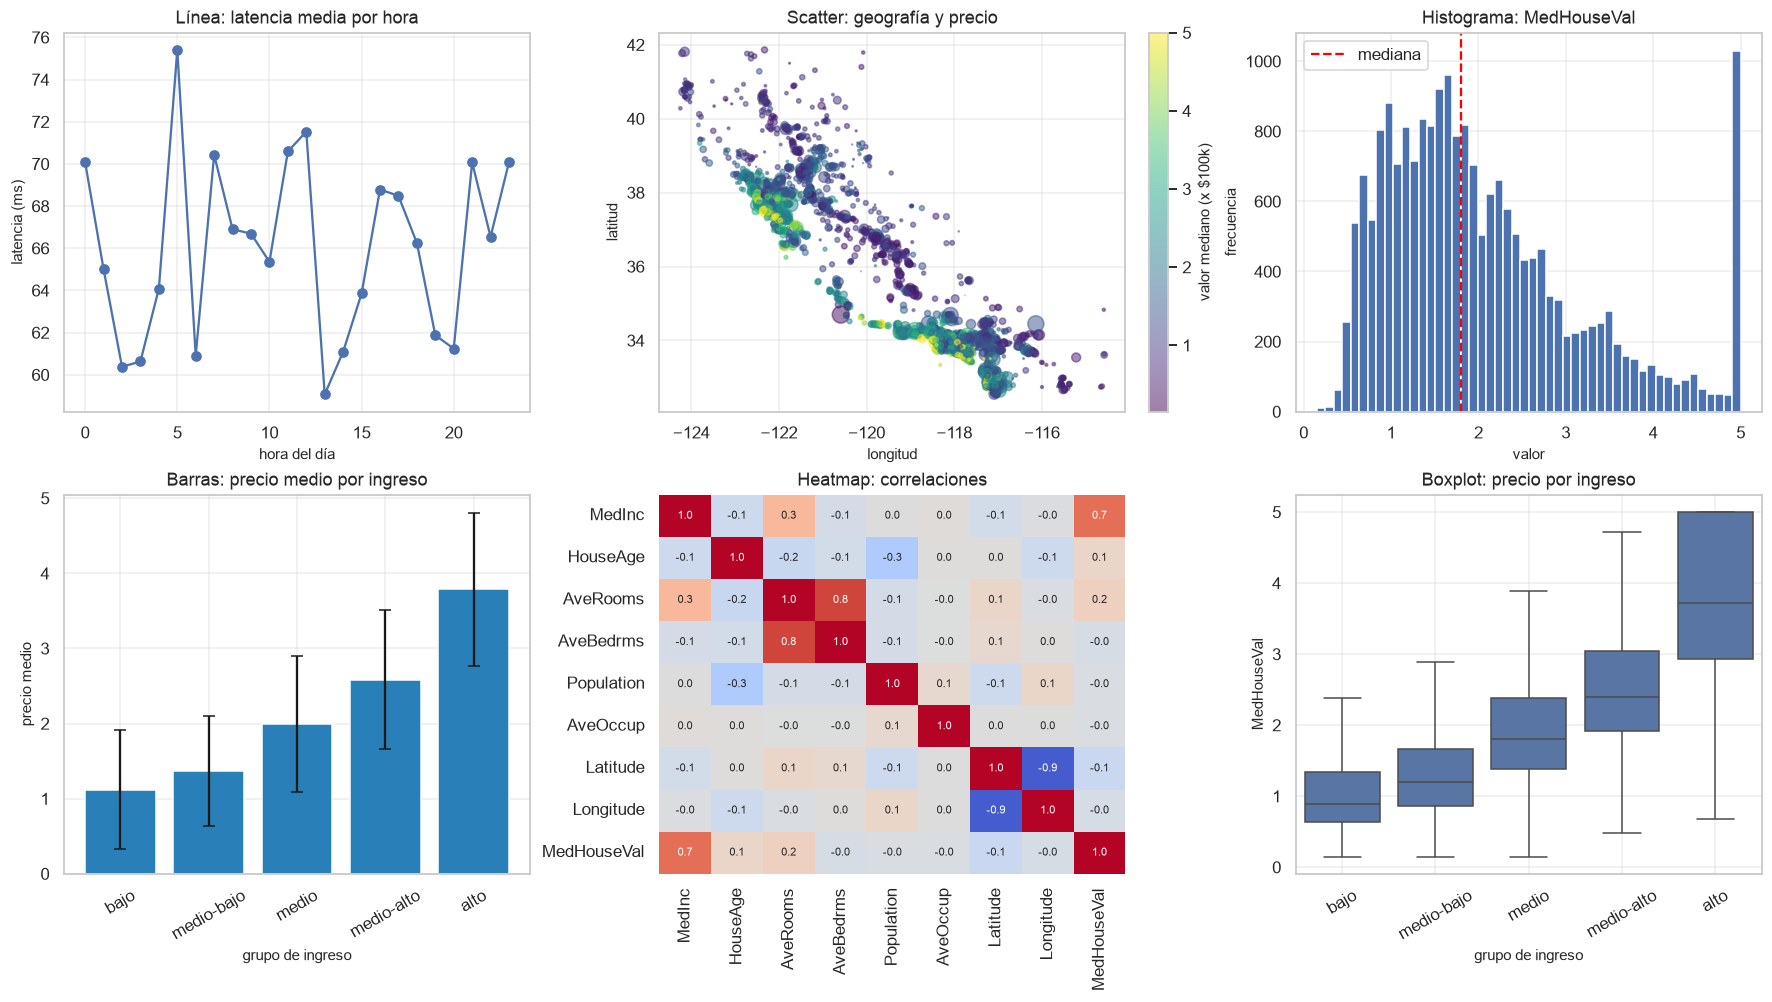

In [20]:
sample = df.sample(5000, random_state=SEED)       # graficar 20.000 puntos satura el scatter: se muestrea
fig, axes = plt.subplots(2, 3, figsize=(16, 9), layout="constrained")

# 1) Línea: latencia media por hora del día
hourly_mean = logs.groupby("hour")["latency_ms"].mean()
axes[0, 0].plot(hourly_mean.index, hourly_mean.values, "o-")
axes[0, 0].set(title="Línea: latencia media por hora", xlabel="hora del día", ylabel="latencia (ms)")

# 2) Scatter: mapa de California; color = precio, tamaño = población
sc = axes[0, 1].scatter(sample["Longitude"], sample["Latitude"], c=sample["MedHouseVal"],
                        s=sample["Population"] / 100, cmap="viridis", alpha=0.5)
fig.colorbar(sc, ax=axes[0, 1], label="valor mediano (x $100k)")
axes[0, 1].set(title="Scatter: geografía y precio", xlabel="longitud", ylabel="latitud")

# 3) Histograma: distribución del target (nótese el tope artificial en 5.0)
axes[0, 2].hist(df["MedHouseVal"], bins=50, edgecolor="white")
axes[0, 2].axvline(df["MedHouseVal"].median(), color="red", ls="--", label="mediana")
axes[0, 2].set(title="Histograma: MedHouseVal", xlabel="valor", ylabel="frecuencia")
axes[0, 2].legend()

# 4) Barras: precio medio por grupo de ingreso (+ barras de error = desviación estándar)
axes[1, 0].bar(stats.index.astype(str), stats["precio_medio"], yerr=stats["precio_std"], capsize=4, color="#2980b9")
axes[1, 0].set(title="Barras: precio medio por ingreso", xlabel="grupo de ingreso", ylabel="precio medio")
axes[1, 0].tick_params(axis="x", rotation=30)

# 5) Heatmap: correlaciones (divergente y centrado en 0 para que el signo sea legible)
corr = df.select_dtypes("number").drop(columns=["val_vs_group"]).corr()
sns.heatmap(corr, ax=axes[1, 1], cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar=False)
axes[1, 1].set(title="Heatmap: correlaciones")

# 6) Boxplot: la distribución del precio dentro de cada grupo
sns.boxplot(data=df, x="income_cat", y="MedHouseVal", ax=axes[1, 2], showfliers=False)
axes[1, 2].set(title="Boxplot: precio por ingreso", xlabel="grupo de ingreso", ylabel="MedHouseVal")
axes[1, 2].tick_params(axis="x", rotation=30)

for ax in axes.ravel():
    ax.grid(True)
plt.show()

**Lectura:** (la línea de latencia es ruido: los logs son sintéticos y no tienen patrón horario real). El ingreso (`MedInc`) es la variable que mejor explica el precio; la geografía importa (la costa es cara); y hay un **techo artificial** en 5.0 que el modelo aprenderá como si fuera real (el notebook 02 lo discute).

### 5.3 Seaborn para análisis exploratorio rápido
seaborn trabaja sobre DataFrames *largos* y facilita comparar por categoría con una sola línea.

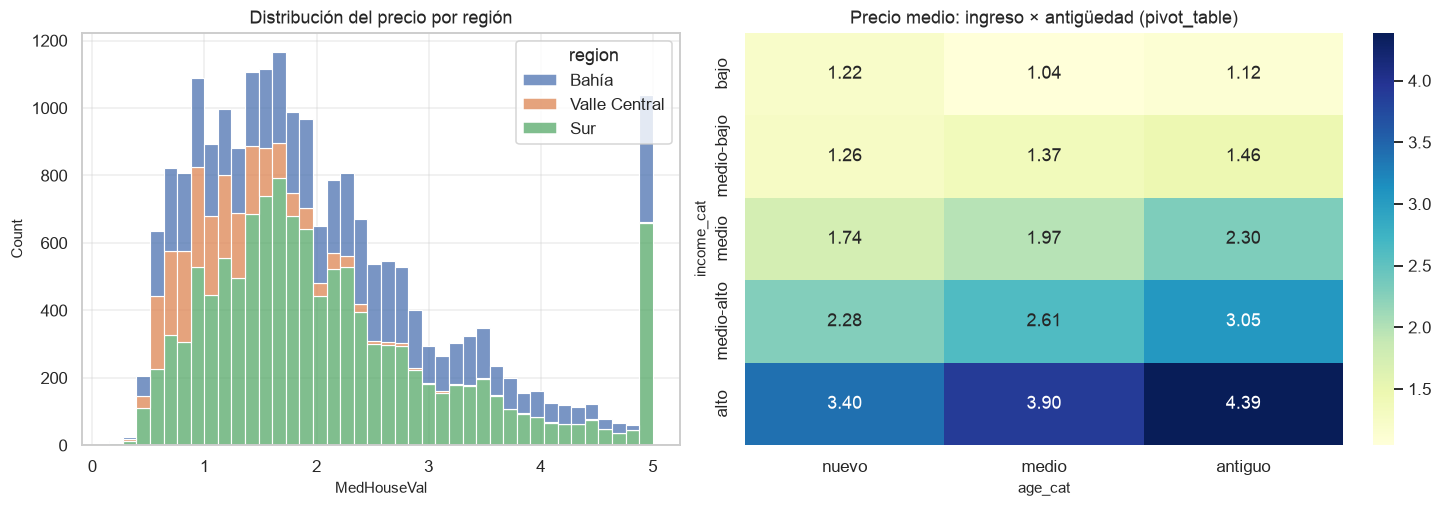

figura guardada en: /var/folders/_t/ttrqn_wj631b9p3_5t5hwbzh0000gn/T/nb01_demo.png | tamaño: 90 KB


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
sns.histplot(data=df, x="MedHouseVal", hue="region", multiple="stack", bins=40, ax=axes[0])
axes[0].set(title="Distribución del precio por región")
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1])
axes[1].set(title="Precio medio: ingreso × antigüedad (pivot_table)")
plt.show()

p = savefig_tmp(fig, "nb01_demo.png")
print("figura guardada en:", p, "| tamaño:", f"{p.stat().st_size/1e3:.0f} KB")

## 6. Workflows: formatos de archivo y EDA en 10 líneas

### 6.1 CSV vs JSON vs Parquet
| Formato | Orientación | Conserva tipos | Compresión | Úsalo para |
|---|---|---|---|---|
| **CSV** | filas, texto | ✗ (todo se re-infiere) | ✗ | intercambio universal, datasets pequeños |
| **JSON / JSON Lines** | filas, texto | parcial | ✗ | APIs, **MongoDB**, logs |
| **Parquet** | **columnas**, binario | ✓ | ✓ | analítica, Big Data, Spark (ver Kleppmann cap. 3: *column-oriented storage*) |

Veamos la diferencia en tamaño, tiempo de lectura y fidelidad de tipos.

In [22]:
tmp = Path(tempfile.mkdtemp(prefix="nb01_"))
paths = {"csv": tmp / "housing.csv", "jsonl": tmp / "housing.jsonl", "parquet": tmp / "housing.parquet"}

df.to_csv(paths["csv"], index=False)
df.to_json(paths["jsonl"], orient="records", lines=True)      # un documento JSON por línea (formato de mongoimport)
df.to_parquet(paths["parquet"], index=False)

readers = {"csv": pd.read_csv, "jsonl": lambda p: pd.read_json(p, lines=True), "parquet": pd.read_parquet}
rows = []
for fmt, p in paths.items():
    back = readers[fmt](p)
    rows.append({"formato": fmt, "tamaño_MB": p.stat().st_size / 1e6,
                 "lectura_ms": time_ms(readers[fmt], p, repeat=3),
                 "conserva category": str(back["income_cat"].dtype) == "category"})
display(pd.DataFrame(rows).set_index("formato").round(2))

,tamaño_MB,lectura_ms,conserva category
formato,,,
csv,2.98,11.36,False
jsonl,6.01,83.95,False
parquet,0.93,5.29,True


**Lectura por chunks** (cuando el archivo no cabe en RAM): se procesa por trozos y se combinan resultados parciales. Es la misma idea que MapReduce (Big Data).

**Opciones de `read_csv` que más ahorran:** `usecols` (solo las columnas necesarias), `dtype` (evita inferencias caras), `parse_dates`, `nrows` (prueba rápida).

In [23]:
total, count = 0.0, 0
for chunk in pd.read_csv(paths["csv"], usecols=["MedHouseVal"], chunksize=5000):
    total += chunk["MedHouseVal"].sum()     # estado parcial que combinamos (sum y count son asociativos)
    count += len(chunk)

assert np.isclose(total / count, df["MedHouseVal"].mean())
print(f"media por chunks = {total/count:.5f} == media en memoria = {df['MedHouseVal'].mean():.5f}")

# JSON legible para humanos (indent) — no usar en archivos grandes
print(df[["MedInc", "MedHouseVal", "city"]].head(2).to_json(orient="records", indent=2))

media por chunks = 2.06856 == media en memoria = 2.06856
[
  {
    "MedInc":8.3252,
    "MedHouseVal":4.526,
    "city":"San Francisco"
  },
  {
    "MedInc":8.3014,
    "MedHouseVal":3.585,
    "city":"San Francisco"
  }
]


### 6.2 EDA en 10 líneas
El helper `quick_eda` (definido arriba) resume forma, memoria, duplicados, tipos, nulos, estadísticos y correlaciones con el target. Es lo primero que ejecutas con cualquier dataset nuevo.

In [24]:
quick_eda(load_housing(), target="MedHouseVal")

shape=(20640, 9) | memoria=1.49 MB | filas duplicadas=0


,dtype,nulls_%,unique,mean,std,min,50%,max
MedInc,float64,0.0,12928,3.871,1.900,0.500,3.535,15.000
HouseAge,float64,0.0,52,28.639,12.586,1.000,29.000,52.000
AveRooms,float64,0.0,19392,5.429,2.474,0.846,5.229,141.909
AveBedrms,float64,0.0,14233,1.097,0.474,0.333,1.049,34.067
Population,float64,0.0,3888,1425.477,1132.462,3.000,1166.000,35682.000
AveOccup,float64,0.0,18841,3.071,10.386,0.692,2.818,1243.333
Latitude,float64,0.0,862,35.632,2.136,32.540,34.260,41.950
Longitude,float64,0.0,844,-119.570,2.004,-124.350,-118.490,-114.310
MedHouseVal,float64,0.0,3842,2.069,1.154,0.150,1.797,5.000


,corr con MedHouseVal
MedInc,0.688
AveRooms,0.152
Latitude,-0.144
HouseAge,0.106
AveBedrms,-0.047


## 7. Cheat sheet de referencia rápida

### NumPy
| Quiero… | Función | Cuándo | Sintaxis |
|---|---|---|---|
| Crear arrays | `zeros`, `ones`, `arange`, `linspace`, `eye` | inicializar | `np.linspace(0, 1, 50)` |
| Aleatorios reproducibles | `default_rng` | siempre que haya azar | `rng = np.random.default_rng(42); rng.normal(size=(3, 3))` |
| Cambiar forma | `reshape`, `ravel`, `T`, `[:, None]` | alinear dimensiones | `a.reshape(-1, 1)` (el `-1` se infiere) |
| Reducir por eje | `sum`, `mean`, `std`, `max`, `argmax` con `axis` | resumir | `X.mean(axis=0)` → una media por columna |
| Condicional vectorizado | `np.where` | if/else sin bucle | `np.where(x > 0, x, 0)` |
| Filtrar | máscara booleana | seleccionar filas | `X[X[:, 0] > 5]` |
| Ordenar / top-k | `argsort`, `argpartition` | rankings | `np.argsort(s)[::-1][:k]` |
| Apilar | `concatenate`, `stack`, `column_stack` | unir arrays | `np.column_stack([a, b])` |
| Producto matricial | `@`, `np.dot` | álgebra lineal | `X.T @ X` |
| Resolver sistema | `linalg.solve` | $Ax=b$ | `np.linalg.solve(A, b)` |
| Mínimos cuadrados | `linalg.lstsq` | regresión | `np.linalg.lstsq(X, y, rcond=None)[0]` |
| Autovalores / SVD | `linalg.eig`, `linalg.svd` | Markov, PCA | `U, s, Vt = np.linalg.svd(A, full_matrices=False)` |
| Comparar floats | `np.allclose`, `np.isclose` | tests | `np.allclose(a, b)` (nunca `==`) |

### pandas
| Quiero… | Función | Cuándo | Sintaxis |
|---|---|---|---|
| Inspeccionar | `info`, `describe`, `head`, `dtypes` | primer vistazo | `df.info()` |
| Seleccionar | `loc` (etiquetas), `iloc` (posiciones) | filas/columnas | `df.loc[df.x > 0, ["a", "b"]]` |
| Filtrar legible | `query` | condiciones simples | `df.query("a > 5 and b == 'x'")` |
| Columna nueva (sin mutar) | `assign` | cadenas | `df.assign(r=lambda d: d.a / d.b)` |
| Resumir por grupo | `groupby().agg` | tablas resumen | `df.groupby("g").agg(m=("x", "mean"))` |
| Feature relativa al grupo | `groupby().transform` | mismo tamaño que df | `df.groupby("g")["x"].transform("mean")` |
| Unir tablas | `merge` | JOIN | `a.merge(b, on="k", how="left", validate="m:1")` |
| Apilar tablas | `concat` | mismas columnas | `pd.concat([a, b], ignore_index=True)` |
| Tabla dinámica | `pivot_table` | cruce de 2 categorías | `df.pivot_table(index="a", columns="b", values="v", aggfunc="mean")` |
| Ancho → largo | `melt` | tidy / seaborn | `df.melt(id_vars="id")` |
| Nulos | `isna`, `fillna`, `dropna` | limpieza | `df["x"].fillna(df["x"].median())` |
| Duplicados | `duplicated`, `drop_duplicates` | limpieza | `df.drop_duplicates(subset=["id"])` |
| Texto | `.str.contains/extract/replace/strip` | columnas de string | `s.str.extract(r"(\d+)")` |
| Fechas | `to_datetime`, `.dt.*`, `resample` | series temporales | `pd.to_datetime(s, errors="coerce")` |
| Discretizar | `cut`, `qcut` | categorías desde numéricos | `pd.qcut(s, 4)` |
| Tipos | `astype`, `to_numeric` | memoria / correcciones | `pd.to_numeric(s, errors="coerce")` |
| Encadenar | `pipe` | funciones propias | `df.pipe(f, arg=1)` |

### matplotlib / seaborn
| Quiero… | Función | Cuándo | Sintaxis |
|---|---|---|---|
| Crear figura | `plt.subplots` | siempre | `fig, ax = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")` |
| Línea | `ax.plot` | series ordenadas | `ax.plot(x, y, label="…")` |
| Dispersión | `ax.scatter` | 2 numéricas (+color/tamaño) | `ax.scatter(x, y, c=z, s=10, alpha=.5)` |
| Histograma | `ax.hist`, `sns.histplot` | distribución | `ax.hist(x, bins=50)` |
| Barras | `ax.bar` | una cifra por categoría | `ax.bar(cats, vals, yerr=err)` |
| Heatmap | `sns.heatmap` | correlaciones, matrices de confusión | `sns.heatmap(c, annot=True, cmap="coolwarm", center=0)` |
| Boxplot | `sns.boxplot` | distribución por categoría | `sns.boxplot(data=df, x="g", y="v")` |
| Etiquetar todo | `ax.set` | siempre | `ax.set(title=…, xlabel=…, ylabel=…)` |
| Guardar | `fig.savefig` | informes | `fig.savefig("f.png", dpi=150, bbox_inches="tight")` |

### Formatos
| Quiero… | Lectura | Escritura |
|---|---|---|
| CSV | `pd.read_csv(p, usecols=…, dtype=…, chunksize=…)` | `df.to_csv(p, index=False)` |
| JSON Lines (MongoDB) | `pd.read_json(p, lines=True)` | `df.to_json(p, orient="records", lines=True)` |
| Parquet | `pd.read_parquet(p)` | `df.to_parquet(p)` |

## 8. Conexiones con el mundo real

**En la industria.** Este stack es el denominador común del trabajo con datos: analistas, científicos e ingenieros de datos lo usan a diario. NumPy es el sustrato de scikit-learn, SciPy, TensorFlow y PyTorch; pandas es la interfaz tabular estándar de prácticamente cualquier librería de ML.

**Telecomunicaciones.** Las redes móviles generan telemetría por celda (tráfico, latencia, tasa de caídas) que se analiza con exactamente el patrón de la sección 4.7: `resample` por ventanas, percentiles altos (p95/p99) y detección de picos. Las muestras de una señal son arrays NumPy; filtros, FFT y proyecciones son álgebra lineal vectorizada.

**Sistemas distribuidos y Big Data.** El procesamiento por *chunks* (sec. 6.1) es una versión local de MapReduce: estados parciales asociativos que se combinan. Parquet es el formato columnar estándar en *data lakes* (Spark, Athena, BigQuery). Cuando el dato supera la RAM, el salto natural es Polars/DuckDB (una máquina) o Spark/Dask (clúster) — mismos conceptos, otra API (se retoma en `14_data_pipelines`).

**Contexto chileno / latinoamericano.** Muchas fuentes de datos públicas se publican como CSV o Excel y son un buen terreno de práctica: portales de datos abiertos del Estado (p. ej. datos.gob.cl), series económicas del Banco Central, eventos sísmicos del Centro Sismológico Nacional, mediciones de calidad del aire o hidrológicas. Suelen traer justo los problemas del Ejercicio 2: separadores de miles con punto (`$1.250.000`), tildes inconsistentes, fechas en formatos mixtos y duplicados.

**Limitaciones y alternativas (honestidad).**
- pandas copia datos con frecuencia y no paraleliza: para > ~1–5 GB, Polars/DuckDB suelen ser 5–50× más rápidos.
- `apply` con `lambda` es un bucle de Python disfrazado: si existe `.str`, `.dt` o una operación vectorizada, úsala.
- matplotlib es verboso; para exploración interactiva, Plotly/Altair son alternativas, y para figuras de publicación matplotlib sigue siendo el estándar.

## 9. Ejercicios progresivos
En cada ejercicio hay una celda **"Tu turno"** vacía antes de la solución: intenta resolverlo ahí (mirando solo el cheat sheet) antes de abrir la solución.

---
### Ejercicio 1 · Reproducir — perfil completo de California Housing
Carga el dataset y, **sin usar `quick_eda`**, produce: (a) forma, (b) tipos de dato, (c) porcentaje de nulos por columna, (d) las 3 variables más correlacionadas con `MedHouseVal`, (e) un heatmap de correlaciones, y (f) cuántos distritos están en el techo del target (`MedHouseVal >= 5.0`; el valor máximo real es 5.00001, así que `== 5.0` no sirve).

In [25]:
# Tu turno (Ejercicio 1): escribe aquí tu solución

**Solución 1**

(a) shape: (20640, 9)
(b) dtypes:
 float64    9
(c) nulos (%): {'MedInc': 0.0, 'HouseAge': 0.0, 'AveRooms': 0.0, 'AveBedrms': 0.0, 'Population': 0.0, 'AveOccup': 0.0, 'Latitude': 0.0, 'Longitude': 0.0, 'MedHouseVal': 0.0}
(d) top-3 correlacionadas:
 MedInc      0.688
AveRooms    0.152
Latitude   -0.144


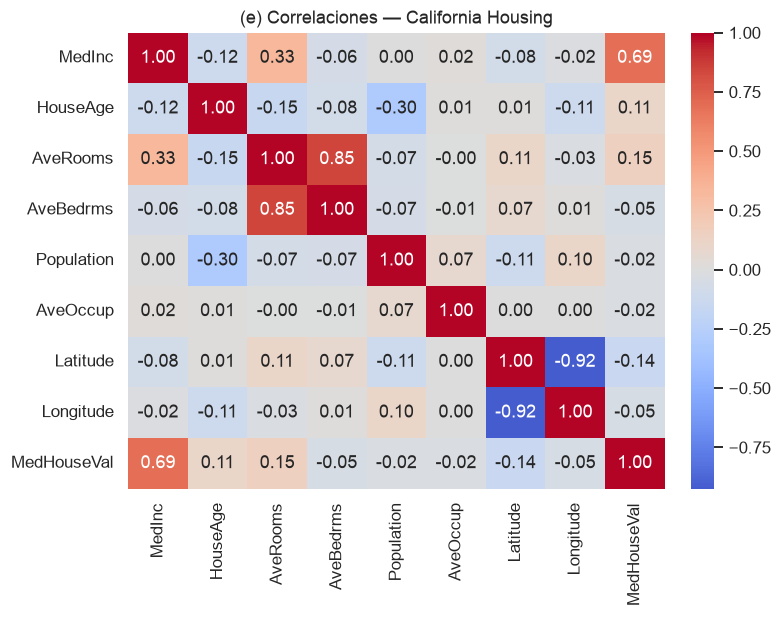

(f) distritos en el techo 5.0: 992 (4.81%) → el modelo no puede predecir valores mayores


In [26]:
housing = load_housing()

print("(a) shape:", housing.shape)
print("(b) dtypes:\n", housing.dtypes.value_counts().to_string())
print("(c) nulos (%):", (housing.isna().mean() * 100).round(2).to_dict())

corr_target = housing.corr()["MedHouseVal"].drop("MedHouseVal")
top3 = corr_target.abs().sort_values(ascending=False).head(3).index
print("(d) top-3 correlacionadas:\n", corr_target[top3].round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 5.5), layout="constrained")
sns.heatmap(housing.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="(e) Correlaciones — California Housing")
plt.show()

capped = (housing["MedHouseVal"] >= 5.0).sum()
print(f"(f) distritos en el techo 5.0: {capped} ({capped / len(housing):.2%}) → el modelo no puede predecir valores mayores")
assert housing.isna().sum().sum() == 0 and top3[0] == "MedInc"

---
### Ejercicio 2 · Aplicar — limpiar un dataset sucio para ML
Te entregan una tabla de clientes con los problemas típicos de datos reales chilenos. Déjala lista para ML:
- eliminar **duplicados exactos**;
- `age`: mezcla de números, `"n/a"` y textos como `"34 años"` → numérico, imputando la mediana y **marcando** qué filas estaban faltantes;
- `salary`: texto tipo `"$1.250.000"` → número;
- `city`: variantes de mayúsculas, espacios y tildes → una sola forma canónica, tipo `category`;
- `signup_date`: fechas inválidas → `NaT`, y derivar `signup_year`.

In [27]:
# Generamos el dataset sucio de forma determinista (no hace falta entender este bloque para el ejercicio)
rng_dirty = np.random.default_rng(7)
n = 300
ages = rng_dirty.integers(18, 71, n)
age_raw = [str(a) for a in ages]
for i in rng_dirty.choice(n, 15, replace=False):  age_raw[i] = "n/a"
for i in rng_dirty.choice(n, 15, replace=False):
    if age_raw[i] != "n/a": age_raw[i] = f"{age_raw[i]} años"

salary = rng_dirty.lognormal(mean=14.0, sigma=0.4, size=n).round(-3).astype(int)
salary_raw = [f"${s:,}".replace(",", ".") for s in salary]

city_variants = ["Santiago", " santiago", "SANTIAGO", "Valparaíso", "valparaiso", "Concepción", "concepcion ", "Antofagasta"]
dates = pd.date_range("2021-01-01", "2025-12-31", periods=n).strftime("%Y-%m-%d").tolist()
for i in rng_dirty.choice(n, 10, replace=False): dates[i] = "31-02-2023"      # fecha imposible

dirty = pd.DataFrame({
    "id": np.arange(n),
    "age": age_raw,
    "salary": salary_raw,
    "city": rng_dirty.choice(city_variants, n),
    "signup_date": dates,
})
dirty = pd.concat([dirty, dirty.sample(20, random_state=1)], ignore_index=True)   # 20 duplicados exactos

display(dirty.sample(6, random_state=3))
print("filas:", len(dirty), "| duplicados:", dirty.duplicated().sum())

,id,age,salary,city,signup_date
154,154,50,$1.085.000,santiago,2023-07-29
314,122,41,$1.109.000,SANTIAGO,2023-01-15
122,122,41,$1.109.000,SANTIAGO,2023-01-15
114,114,39,$581.000,Concepción,2022-11-27
257,257,27,$1.065.000,concepcion,2025-04-18
259,259,36,$718.000,Concepción,2025-04-30


filas: 320 | duplicados: 20


In [28]:
# Tu turno (Ejercicio 2): escribe aquí tu función clean_customers(dirty)

**Solución 2**

In [29]:
def clean_customers(raw: pd.DataFrame) -> pd.DataFrame:
    out = raw.drop_duplicates().copy()

    # age: extraer los dígitos; "n/a" no tiene dígitos → NaN. Marcamos ANTES de imputar
    out["age"] = pd.to_numeric(out["age"].str.extract(r"(\d+)")[0], errors="coerce")
    out["age_missing"] = out["age"].isna().astype("int8")
    out["age"] = out["age"].fillna(out["age"].median())

    # salary: quitar todo lo que no sea dígito ('$' y los puntos de miles chilenos)
    out["salary"] = pd.to_numeric(out["salary"].str.replace(r"\D", "", regex=True), errors="raise")

    # city: minúsculas, sin espacios y sin tildes (NFKD separa letra + tilde; ascii/ignore descarta la tilde)
    out["city"] = (out["city"].str.strip().str.lower()
                   .str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii")
                   .astype("category"))

    # fechas: errors="coerce" convierte lo inválido en NaT en lugar de abortar
    out["signup_date"] = pd.to_datetime(out["signup_date"], format="%Y-%m-%d", errors="coerce")
    out["signup_year"] = out["signup_date"].dt.year.astype("Int16")
    return out.reset_index(drop=True)


clean = clean_customers(dirty)

# Verificaciones: un pipeline de limpieza sin tests es una promesa, no una garantía
assert clean.duplicated().sum() == 0 and len(clean) == 300
assert clean["age"].notna().all() and clean["age_missing"].sum() > 0
assert pd.api.types.is_numeric_dtype(clean["salary"])
assert set(clean["city"].cat.categories) == {"santiago", "valparaiso", "concepcion", "antofagasta"}
print("fechas inválidas detectadas (NaT):", clean["signup_date"].isna().sum())
clean.info()
display(clean.head())

fechas inválidas detectadas (NaT): 10
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           300 non-null    int64         
 1   age          300 non-null    float64       
 2   salary       300 non-null    int64         
 3   city         300 non-null    category      
 4   signup_date  290 non-null    datetime64[us]
 5   age_missing  300 non-null    int8          
 6   signup_year  290 non-null    Int16         
dtypes: Int16(1), category(1), datetime64[us](1), float64(1), int64(2), int8(1)
memory usage: 11.0 KB


,id,age,salary,city,signup_date,age_missing,signup_year
0,0,68.0,2052000,concepcion,2021-01-01,0,2021
1,1,51.0,982000,santiago,2021-01-07,0,2021
2,2,54.0,1351000,santiago,2021-01-13,0,2021
3,3,65.0,1186000,santiago,2021-01-19,0,2021
4,4,48.0,1008000,concepcion,2021-01-25,0,2021


---
### Ejercicio 3 · Integrar — de California Housing a documentos para MongoDB (Big Data)
Conecta este notebook con el proyecto ETL de **Big Data**:
1. Divide el mapa en una **grilla de 0.5° × 0.5°** (celda = `floor(coord / 0.5) * 0.5`).
2. Para cada celda calcula: nº de distritos, población total, ingreso medio y precio medio/mediano; descarta celdas con menos de 20 distritos.
3. Exporta cada celda como un **documento JSON** con un campo `location` en formato **GeoJSON** (`{"type": "Point", "coordinates": [lon, lat]}`, en ese orden) y guárdalo en *JSON Lines* (`outputs/california_cells.jsonl`) listo para `mongoimport`.
4. Verifica que el archivo es JSON válido (sin `NaN`, que no existe en JSON) releyéndolo línea a línea.

In [30]:
# Tu turno (Ejercicio 3): escribe aquí tu solución

**Solución 3**

In [31]:
GRID = 0.5
geo = df[["Latitude", "Longitude", "Population", "MedInc", "MedHouseVal"]].copy()
geo["lat_cell"] = np.floor(geo["Latitude"] / GRID) * GRID
geo["lon_cell"] = np.floor(geo["Longitude"] / GRID) * GRID

cells = (geo.groupby(["lat_cell", "lon_cell"])
            .agg(n_districts=("MedHouseVal", "size"),
                 population=("Population", "sum"),
                 income_mean=("MedInc", "mean"),
                 price_mean=("MedHouseVal", "mean"),
                 price_median=("MedHouseVal", "median"))
            .query("n_districts >= 20")
            .round(4)
            .reset_index())
print(f"{len(cells)} celdas con >= 20 distritos")

# Centro de la celda como coordenada del documento; GeoJSON exige [lon, lat]
cells["location"] = [{"type": "Point", "coordinates": [lon + GRID / 2, lat + GRID / 2]}
                     for lat, lon in zip(cells["lat_cell"], cells["lon_cell"])]
cells["_id"] = [f"cell_{lat:.1f}_{lon:.1f}" for lat, lon in zip(cells["lat_cell"], cells["lon_cell"])]

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
out_path = out_dir / "california_cells.jsonl"

# to_json convierte los tipos NumPy a tipos JSON nativos (y NaN → null) que json.dumps no maneja bien
records = json.loads(cells.drop(columns=["lat_cell", "lon_cell"]).to_json(orient="records"))
with out_path.open("w", encoding="utf-8") as f:
    for rec in records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

# Verificación: cada línea es JSON válido y el GeoJSON tiene el orden correcto lon, lat
with out_path.open(encoding="utf-8") as f:
    docs = [json.loads(line) for line in f]
assert len(docs) == len(cells)
assert all(-125 < d["location"]["coordinates"][0] < -114 and 32 < d["location"]["coordinates"][1] < 43 for d in docs)

print("Primer documento:\n", json.dumps(docs[0], indent=2, ensure_ascii=False))
print(f"\nCarga en MongoDB:  mongoimport --db housing --collection cells --file {out_path}")

73 celdas con >= 20 distritos
Primer documento:
 {
  "n_districts": 1033,
  "population": 1401133.0,
  "income_mean": 3.5934,
  "price_mean": 1.9267,
  "price_median": 1.625,
  "location": {
    "type": "Point",
    "coordinates": [
      -117.25,
      32.75
    ]
  },
  "_id": "cell_32.5_-117.5"
}

Carga en MongoDB:  mongoimport --db housing --collection cells --file outputs/california_cells.jsonl


## 10. Conclusión y siguiente paso

**Resumen en 5 líneas**
1. NumPy es rápido porque guarda valores contiguos y opera en C: **vectoriza y usa broadcasting** en lugar de bucles.
2. El álgebra lineal (`solve`, `lstsq`, `eig`, `svd`) es la base matemática de regresión, Markov y PCA.
3. pandas se reduce a *split-apply-combine*, *joins* y *reshape*; escribe cadenas con `assign`/`pipe`, sin mutar el original.
4. Con matplotlib usa siempre `fig, ax`; elige el gráfico según la pregunta (línea, scatter, hist, barras, heatmap, boxplot).
5. Parquet conserva tipos y es columnar; el stack vive en RAM, y para más escala se pasa a Polars/DuckDB/Spark con los mismos conceptos.

**Continúa en:** `02_end_to_end_ml.ipynb` — un proyecto de ML completo (con este mismo dataset) donde estas herramientas se convierten en un `Pipeline` reproducible.

**Para profundizar**
- *VanderPlas, Python Data Science Handbook:* cap. 2 (NumPy: *Computation on Arrays: Broadcasting*, *Fancy Indexing*), cap. 3 (pandas: *Combining Datasets*, *Aggregation and Grouping*, *Pivot Tables*, *Vectorized String Operations*, *Working with Time Series*), cap. 4 (matplotlib).
- *Kleppmann, DDIA:* cap. 3 (*Column-Oriented Storage*, por qué Parquet es rápido) y cap. 4 (codificación de datos: JSON vs formatos binarios).
- *Géron, Hands-On ML:* cap. 2, sección *Get the Data* y *Explore and Visualize* (el mismo dataset que aquí).

---

# Parte II · De tablas planas a un catálogo de feria

> **Por qué existe esta parte.** Todo lo anterior trabaja con una tabla rectangular
> (California Housing: 20.640 filas × 9 columnas numéricas). El proyecto del ramo no
> tiene esa forma: tiene **documentos anidados**, **listas de etiquetas de largo
> variable**, **texto escrito por humanos** y **varias fuentes con esquemas distintos**.
> Esta parte cierra exactamente ese salto, que es donde se atasca el 90 % de los
> proyectos de Big Data.
>
> **Qué vas a poder hacer al terminarla**
>
> 1. Convertir JSON anidado ↔ DataFrame ↔ documentos de MongoDB sin perder información.
> 2. Normalizar texto y etiquetas para que `"Ciencia-Ficción"`, `"ciencia ficcion"` y
>    `"SciFi"` sean **la misma cosa** — el requisito silencioso de todo sistema de
>    recomendación.
> 3. Construir y validar una **taxonomía de etiquetas en dos niveles**
>    (general → específico), que es lo que permite comparar cosas de dominios distintos.
> 4. Generar un **catálogo sintético reproducible** que vas a reutilizar en NB-02
>    (MongoDB), NB-03 (similitud) y NB-04 (recorrido).

### El dominio de trabajo: EXPOLIBRO

Para todo lo que sigue usamos una feria **análoga** a la tuya, no la tuya:
**EXPOLIBRO**, una feria del libro.

| Pieza                  | EXPOLIBRO (lo que programamos aquí) |
|------------------------|-------------------------------------|
| Stand                  | Una **editorial**                   |
| Dominios del catálogo  | `libro`, `revista`, `charla`        |
| Ítem del catálogo      | Una obra publicada                  |
| Evento con horario     | Charla de autor en un escenario     |
| Etiqueta               | 2 niveles: `ficcion` → `fantasia`   |
| Asistente              | Visitante con gustos declarados     |

La estructura es la misma que vas a necesitar; **los datos no**. Eso es a propósito:
el código de abajo te enseña la técnica, y las decisiones de modelado de tu feria
siguen siendo tuyas. Al final de cada bloque hay un recuadro **ZONA DE DECISIÓN**
con las preguntas que tienes que responder tú (o discutir con tu grupo) para
trasladar la técnica a tu propio dominio.

## 11. Datos anidados: JSON ↔ DataFrame ↔ documentos

### 11.1 La intuición: dos formas de guardar lo mismo

Un catálogo de feria se puede guardar de dos maneras, y las dos son correctas:

```
FORMA TABULAR (relacional, "plana")        FORMA DOCUMENTO (MongoDB, "anidada")
┌──────┬──────────┬───────────┐            {
│ obra │ titulo   │ stand_id  │              "_id": "OB-001",
├──────┼──────────┼───────────┤              "titulo": "El mapa del tiempo",
│ OB-1 │ El mapa… │ ED-07     │              "stand": {"id": "ED-07",
└──────┴──────────┴───────────┘                        "nombre": "Austral"},
┌──────┬──────────┬───────────┐              "tags": [
│ obra │ general  │ especifico│                {"general": "ficcion",
├──────┼──────────┼───────────┤                 "especifico": "fantasia"},
│ OB-1 │ ficcion  │ fantasia  │                {"general": "ficcion",
│ OB-1 │ ficcion  │ steampunk │                 "especifico": "steampunk"}
└──────┴──────────┴───────────┘              ]
                                            }
3 tablas, 1 JOIN por consulta               1 documento, 1 lectura
```

**La regla que hay detrás** (Kleppmann, *DDIA* cap. 2): elegir entre una y otra no es
cuestión de gusto, es cuestión de **patrón de acceso**. Si casi siempre lees la obra
*junto con* sus etiquetas y su stand, el documento gana: una sola lectura de disco en
vez de tres. Si necesitas consultar las etiquetas por su cuenta, cruzarlas entre
dominios y actualizarlas sin tocar las obras, la forma tabular (o una colección
aparte) gana.

Lo que no puedes hacer es *ignorar* la pregunta: esa decisión es la que te va a costar
o ahorrar I/O en toda la vida del proyecto, y es exactamente el cálculo de costos que
viste en las Clases 1–4.

### 11.2 `json_normalize`: aplanar sin perder nada

In [32]:
# === Imports de la Parte II (esta sección es autocontenida) ===
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# Un catálogo tal como llegaría de una API: anidado, con listas de largo variable.
catalogo_json = [
    {"_id": "OB-001", "titulo": "El mapa del tiempo", "anio": 2018,
     "stand": {"id": "ED-07", "nombre": "Austral", "pasillo": "B"},
     "tags": [{"general": "ficcion", "especifico": "fantasia"},
              {"general": "ficcion", "especifico": "steampunk"}]},
    {"_id": "OB-002", "titulo": "Historia mínima de Chile", "anio": 2021,
     "stand": {"id": "ED-02", "nombre": "Pehuén", "pasillo": "A"},
     "tags": [{"general": "no_ficcion", "especifico": "historia"}]},
    {"_id": "OB-003", "titulo": "Álgebra para impacientes", "anio": 2023,
     "stand": {"id": "ED-11", "nombre": "Tecnos", "pasillo": "C"},
     "tags": [{"general": "tecnico", "especifico": "matematicas"},
              {"general": "no_ficcion", "especifico": "divulgacion"}]},
]

# record_path="tags" -> una fila POR ETIQUETA (la lista se vuelve filas)
# meta=[...]         -> columnas que se repiten en cada fila hija
largo = pd.json_normalize(
    catalogo_json,
    record_path="tags",
    meta=["_id", "titulo", "anio", ["stand", "id"], ["stand", "nombre"]],
    sep="_",
)
print("FORMA LARGA (una fila por etiqueta) — para agrupar, contar y cruzar:")
display(largo)

# Sin record_path: una fila POR OBRA; los dicts anidados se aplanan con sep,
# pero la LISTA de tags queda como objeto Python dentro de la celda.
ancho = pd.json_normalize(catalogo_json, sep="_")
print("\nFORMA ANCHA (una fila por obra) — para mostrar y para volver a documento:")
display(ancho)
print("tipo de la celda 'tags':", type(ancho.loc[0, "tags"]).__name__)

FORMA LARGA (una fila por etiqueta) — para agrupar, contar y cruzar:


,general,especifico,_id,titulo,anio,stand_id,stand_nombre
0,ficcion,fantasia,OB-001,El mapa del tiempo,2018,ED-07,Austral
1,ficcion,steampunk,OB-001,El mapa del tiempo,2018,ED-07,Austral
2,no_ficcion,historia,OB-002,Historia mínima de Chile,2021,ED-02,Pehuén
3,tecnico,matematicas,OB-003,Álgebra para impacientes,2023,ED-11,Tecnos
4,no_ficcion,divulgacion,OB-003,Álgebra para impacientes,2023,ED-11,Tecnos



FORMA ANCHA (una fila por obra) — para mostrar y para volver a documento:


,_id,titulo,anio,tags,stand_id,stand_nombre,stand_pasillo
0,OB-001,El mapa del tiempo,2018,"[{'general': 'ficcion', 'especifico': 'fantasi...",ED-07,Austral,B
1,OB-002,Historia mínima de Chile,2021,"[{'general': 'no_ficcion', 'especifico': 'hist...",ED-02,Pehuén,A
2,OB-003,Álgebra para impacientes,2023,"[{'general': 'tecnico', 'especifico': 'matemat...",ED-11,Tecnos,C


tipo de la celda 'tags': list


**Qué deberías ver:** la misma información dos veces. En la forma larga hay **5 filas**
(obra 1 con 2 etiquetas + obra 2 con 1 + obra 3 con 2) y columnas `general` /
`especifico` ya desanidadas. En la forma ancha hay **3 filas** y la columna
`stand_id` / `stand_nombre` aplanadas con `sep="_"`, pero `tags` sigue conteniendo
una **lista de diccionarios**.

Las dos formas sirven para cosas distintas, y conviene tenerlo clarísimo:

| Necesito…                                    | Forma a usar |
|----------------------------------------------|--------------|
| contar cuántas obras hay por etiqueta         | **larga** (`groupby`) |
| calcular similitud entre obras                | **larga** → matriz multi-hot (§ NB-03) |
| mostrar una ficha de obra                     | **ancha** |
| insertar en MongoDB                           | **ancha**, reconstruyendo el anidado |
| filtrar "obras con la etiqueta X"             | cualquiera (en Mongo: índice *multikey*) |

In [33]:
# explode: la contraparte de json_normalize cuando la lista YA está en una columna
plano = ancho.explode("tags", ignore_index=True)
plano = plano.join(pd.json_normalize(plano.pop("tags")))     # pop evita duplicar la columna
print("ancho.explode('tags') + json_normalize  ==  forma larga:")
display(plano[["_id", "titulo", "general", "especifico"]])

# Verificación honesta: ¿llegamos al mismo sitio por los dos caminos?
cols = ["_id", "titulo", "general", "especifico"]
iguales = plano[cols].equals(largo[cols])
print(f"\n¿explode reproduce json_normalize? {iguales}")

# El camino de vuelta: de forma larga a documentos. groupby + to_dict por grupo.
docs = (plano
        .groupby(["_id", "titulo", "anio", "stand_id", "stand_nombre"], as_index=False)
        .apply(lambda g: pd.Series({
            "tags": g[["general", "especifico"]].to_dict("records")}), include_groups=False))
print("\nDe vuelta a documentos (primer registro):")
print(json.dumps(docs.iloc[0].to_dict(), ensure_ascii=False, indent=2)[:400])

ancho.explode('tags') + json_normalize  ==  forma larga:


,_id,titulo,general,especifico
0,OB-001,El mapa del tiempo,ficcion,fantasia
1,OB-001,El mapa del tiempo,ficcion,steampunk
2,OB-002,Historia mínima de Chile,no_ficcion,historia
3,OB-003,Álgebra para impacientes,tecnico,matematicas
4,OB-003,Álgebra para impacientes,no_ficcion,divulgacion



¿explode reproduce json_normalize? True

De vuelta a documentos (primer registro):
{
  "_id": "OB-001",
  "titulo": "El mapa del tiempo",
  "anio": 2018,
  "stand_id": "ED-07",
  "stand_nombre": "Austral",
  "tags": [
    {
      "general": "ficcion",
      "especifico": "fantasia"
    },
    {
      "general": "ficcion",
      "especifico": "steampunk"
    }
  ]
}


### ⚠️ Troubleshooting — los tres errores que te van a pasar al insertar en MongoDB

Estos tres aparecen *siempre*, y el mensaje de error no dice qué hacer. Apréndetelos
ahora y te ahorras una tarde en la Entrega 2.

| Síntoma | Causa real | Arreglo |
|---|---|---|
| `InvalidDocument: cannot encode object: 3` (o `int64`) | pandas entrega `np.int64` / `np.float64`, que **no son** tipos BSON | `int(x)`, `float(x)`, o `df.astype(object).where(df.notna(), None)` antes de insertar |
| Campos con `NaN` que en Mongo aparecen como `nan` | `NaN` es un **float válido**: se inserta sin error y contamina las consultas | convertir a `None` explícitamente: `df.where(df.notna(), None)` |
| `Timestamp('2026-11-02')` se guarda raro | pandas usa `Timestamp`; BSON usa `datetime` | `.dt.to_pydatetime()` o `.to_pydatetime()` |
| `ValueError: NaTType does not support utcoffset` | una fecha **nula** (`NaT`) sobrevive a `to_pydatetime()` y llega a BSON | mapear `NaT` → `None` **antes**: `s.map(lambda v: None if pd.isna(v) else v.to_pydatetime())` |

El último es especialmente traicionero porque el mensaje no menciona ni la columna ni
la fila: `utcoffset` no aparece en tu código por ninguna parte. Si lo ves, busca una
fecha nula.

La causa de fondo es una sola: **pandas y BSON tienen sistemas de tipos distintos.**
pandas optimiza para cálculo vectorizado (por eso `int64`, por eso `NaN`); BSON
optimiza para serializar y transmitir. El borde entre los dos hay que cruzarlo a mano.

In [34]:
def a_documentos(df: pd.DataFrame) -> list[dict]:
    """DataFrame -> lista de dicts seguros para BSON.

    Hace las tres conversiones del cuadro de arriba de una vez. Úsala SIEMPRE
    como última escala antes de insert_many: es barata y te ahorra el 100 % de
    los InvalidDocument.
    """
    limpio = df.copy()
    for col in limpio.columns:
        s = limpio[col]
        if pd.api.types.is_datetime64_any_dtype(s):
            # OJO DOBLE: (1) NaT sobrevive a to_pydatetime() y revienta BSON con un
            # "NaTType does not support utcoffset" que no dice nada; (2) si usas
            # s.map(...) pandas INFIERE datetime64 en el resultado y te vuelve a
            # meter el NaT. Hay que forzar dtype=object para que el None sobreviva.
            limpio[col] = pd.Series(
                [None if pd.isna(v) else v.to_pydatetime() for v in s],
                index=limpio.index, dtype=object)
        elif pd.api.types.is_integer_dtype(s):
            limpio[col] = s.astype(object).map(lambda v: None if pd.isna(v) else int(v))
        elif pd.api.types.is_float_dtype(s):
            limpio[col] = s.astype(object).map(lambda v: None if pd.isna(v) else float(v))
    # object dtype: los NaN sueltos siguen siendo float('nan') -> a None
    return [{k: (None if (isinstance(v, float) and np.isnan(v)) else v)
             for k, v in rec.items()} for rec in limpio.to_dict("records")]


prueba = pd.DataFrame({"n": pd.array([1, 2, None], dtype="Int64"),
                       "precio": [9.9, np.nan, 3.0],
                       "fecha": pd.to_datetime(["2026-11-02", "2026-11-16", None])})
docs_prueba = a_documentos(prueba)
for d in docs_prueba:
    print({k: (type(v).__name__, v) for k, v in d.items()})

# La prueba que importa: ¿lo acepta BSON de verdad?
try:
    from bson import BSON
    for d in docs_prueba:
        BSON.encode(d)
    print("\n✅ Los 3 documentos son BSON-válidos (ni un np.int64, ni un NaN suelto).")
except ImportError:
    print("\n(pymongo no instalado aquí; la verificación de BSON corre en NB-02)")

{'n': ('float', 1.0), 'precio': ('float', 9.9), 'fecha': ('datetime', datetime.datetime(2026, 11, 2, 0, 0))}
{'n': ('float', 2.0), 'precio': ('NoneType', None), 'fecha': ('datetime', datetime.datetime(2026, 11, 16, 0, 0))}
{'n': ('NoneType', None), 'precio': ('float', 3.0), 'fecha': ('NoneType', None)}



✅ Los 3 documentos son BSON-válidos (ni un np.int64, ni un NaN suelto).


### 📊 Resumen visual — datos anidados

```
   API / CSV / scraping                                      MongoDB
   ────────────────────                                      ───────
   JSON anidado  ──json_normalize(record_path)──►  forma LARGA  ──► agrupar, contar,
        │                                          (1 fila/tag)      similitud (NB-03)
        │
        └────────json_normalize(sep="_")────────►  forma ANCHA  ──a_documentos()──►
                                                   (1 fila/obra)     insert_many()
                           ▲                            │
                           └───── explode() ────────────┘
```

---

## 12. Texto y etiquetas: el trabajo invisible que decide si tu recomendador sirve

### 12.1 El problema, con números

Supón que tu feria recibe el catálogo de tres fuentes distintas: una editorial manda
`"Ciencia-Ficción"`, otra `"ciencia ficcion"`, y el formulario de un expositor dice
`"SciFi "` (con espacio al final). Para Python son **tres strings distintos**. Para
MongoDB son tres claves distintas. Para tu recomendador son tres géneros que no se
parecen en nada.

El resultado no es un error ni una excepción: es un sistema que **funciona y entrega
malas recomendaciones**, que es mucho peor, porque nadie se da cuenta hasta la
presentación.

**La regla:** no existe el "texto sucio" y el "texto limpio". Existe un **texto
canónico** que tú defines, y una función que lleva cualquier entrada hacia él.

In [35]:
def normalizar(texto: str) -> str:
    """Lleva cualquier variante de escritura a una forma canónica.

    Los 4 pasos, en este orden exacto (el orden importa):
      1. NFKD + descartar marcas: separa 'ó' en 'o' + tilde, y bota la tilde.
         Así 'Ficción' y 'Ficcion' colapsan. (unicodedata, biblioteca estándar)
      2. minúsculas: 'SciFi' -> 'scifi'.
      3. todo lo que no sea letra/número -> '_' : guiones, espacios y puntos
         dejan de importar.
      4. colapsar '_' repetidos y recortar los de los extremos.
    """
    sin_tildes = "".join(c for c in unicodedata.normalize("NFKD", texto)
                         if not unicodedata.combining(c))
    s = re.sub(r"[^a-z0-9]+", "_", sin_tildes.lower())
    return re.sub(r"_+", "_", s).strip("_")


variantes = ["Ciencia-Ficción", "ciencia ficcion", "  CIENCIA   FICCION  ",
             "Ciencia_Ficción", "ciencia.ficción"]
for v in variantes:
    print(f"{v!r:30} -> {normalizar(v)!r}")
print(f"\n¿Las {len(variantes)} variantes colapsan en UNA sola forma? "
      f"{len({normalizar(v) for v in variantes}) == 1}")

'Ciencia-Ficción'              -> 'ciencia_ficcion'
'ciencia ficcion'              -> 'ciencia_ficcion'
'  CIENCIA   FICCION  '        -> 'ciencia_ficcion'
'Ciencia_Ficción'              -> 'ciencia_ficcion'
'ciencia.ficción'              -> 'ciencia_ficcion'

¿Las 5 variantes colapsan en UNA sola forma? True


### 12.2 Normalizar no basta: hacen falta sinónimos

`normalizar` resuelve la ortografía, pero **no** el vocabulario: `"scifi"`,
`"ciencia_ficcion"` y `"cf"` siguen siendo tres etiquetas distintas aunque las tres
estén perfectamente normalizadas.

Para eso se necesita un **diccionario de sinónimos** explícito, escrito a mano. No hay
atajo automático que sirva: es una decisión de dominio, y por eso es tuya.

> **Idea clave.** La taxonomía de etiquetas no es un detalle de implementación: es
> **el modelo de datos** de un sistema de recomendación por contenido. Si dos dominios
> no comparten vocabulario, no se pueden comparar, y la recomendación cruzada que
> justifica todo el proyecto deja de existir.

In [36]:
# --- La taxonomía: dos niveles, general -> específicos ---
# El nivel GENERAL es el que permite comparar entre dominios distintos
# (una revista y una charla pueden no compartir el específico pero sí el general).
TAXONOMIA = {
    "ficcion":    ["fantasia", "ciencia_ficcion", "policial", "romance", "terror",
                   "steampunk"],
    "no_ficcion": ["historia", "biografia", "ensayo", "divulgacion"],
    "infantil":   ["album_ilustrado", "juvenil"],
    "tecnico":    ["programacion", "matematicas", "diseno"],
}

# --- Sinónimos: variante escrita por un humano -> etiqueta canónica ---
SINONIMOS = {
    "scifi": "ciencia_ficcion", "cf": "ciencia_ficcion", "sci_fi": "ciencia_ficcion",
    "fantastico": "fantasia", "fantasy": "fantasia",
    "negra": "policial", "thriller": "policial", "misterio": "policial",
    "horror": "terror",
    "ensayos": "ensayo", "divulgacion_cientifica": "divulgacion",
    "infantil_juvenil": "juvenil", "ya": "juvenil",
    "coding": "programacion", "software": "programacion",
    "mates": "matematicas", "math": "matematicas",
}

# Índice inverso: específico -> general. Se construye, no se escribe a mano:
# escribirlo dos veces es garantía de que algún día se desincronizan.
GENERAL_DE = {esp: gen for gen, especificos in TAXONOMIA.items() for esp in especificos}
print(f"{len(GENERAL_DE)} etiquetas específicas bajo {len(TAXONOMIA)} generales")


def canonizar(etiqueta: str) -> tuple[str, str] | None:
    """'Sci-Fi ' -> ('ficcion', 'ciencia_ficcion').  Desconocida -> None."""
    e = normalizar(etiqueta)
    e = SINONIMOS.get(e, e)                 # aplicar sinónimo si existe
    general = GENERAL_DE.get(e)
    return (general, e) if general else None


for prueba in ["Sci-Fi ", "THRILLER", "fantasía", "Matemáticas", "cocina", "mates"]:
    print(f"{prueba!r:16} -> {canonizar(prueba)}")

15 etiquetas específicas bajo 4 generales
'Sci-Fi '        -> ('ficcion', 'ciencia_ficcion')
'THRILLER'       -> ('ficcion', 'policial')
'fantasía'       -> ('ficcion', 'fantasia')
'Matemáticas'    -> ('tecnico', 'matematicas')
'cocina'         -> None
'mates'          -> ('tecnico', 'matematicas')


**Qué deberías ver:** las cinco primeras resuelven a un par `(general, específico)`;
`"cocina"` devuelve `None` porque **no está en la taxonomía**.

Ese `None` es lo más valioso de la función. Un sistema que acepta etiquetas
desconocidas en silencio acumula basura durante semanas y nadie lo nota. Uno que las
**reporta** te obliga a tomar una decisión consciente cada vez: ¿es un sinónimo que
falta?, ¿una etiqueta nueva que hay que agregar a la taxonomía?, ¿o un error de tipeo
que hay que rechazar?

Esto es lo mismo que viste en el ETL de NB-02 con el `ETLReport`: **nunca descartes
filas en silencio.**

In [37]:
def auditar_etiquetas(etiquetas_crudas: list[str]) -> pd.DataFrame:
    """Informe de cobertura: qué entra, qué se traduce y qué queda fuera.

    Esta tabla es lo primero que hay que mirar cuando llega un catálogo nuevo:
    dice en una pantalla cuánto de los datos entiende tu taxonomía.
    """
    filas = []
    for cruda in etiquetas_crudas:
        res = canonizar(cruda)
        filas.append({"cruda": cruda, "normalizada": normalizar(cruda),
                      "general": res[0] if res else None,
                      "especifico": res[1] if res else None,
                      "estado": "ok" if res else "DESCONOCIDA"})
    return pd.DataFrame(filas)


crudas = ["Ciencia-Ficción", "scifi", "Fantasía", "policial", "Cocina", "HISTORIA",
          "mates", "jardinería", "Terror", "horror"]
informe = auditar_etiquetas(crudas)
display(informe)

cobertura = (informe["estado"] == "ok").mean()
desconocidas = informe.loc[informe["estado"] == "DESCONOCIDA", "normalizada"].tolist()
print(f"Cobertura de la taxonomía: {cobertura:.0%}")
print(f"Etiquetas que hay que decidir a mano: {desconocidas}")

# Y el conteo que de verdad importa: ¿cuántas etiquetas distintas quedan
# después de canonizar? Si el número no BAJA, la normalización no sirvió de nada.
antes = len(set(crudas))
despues = len({c[1] for e in crudas if (c := canonizar(e))})
print(f"\nEtiquetas distintas: {antes} crudas -> {despues} canónicas "
      f"(reducción del {1 - despues / antes:.0%})")

,cruda,normalizada,general,especifico,estado
0,Ciencia-Ficción,ciencia_ficcion,ficcion,ciencia_ficcion,ok
1,scifi,scifi,ficcion,ciencia_ficcion,ok
2,Fantasía,fantasia,ficcion,fantasia,ok
3,policial,policial,ficcion,policial,ok
4,Cocina,cocina,NaN,NaN,DESCONOCIDA
5,HISTORIA,historia,no_ficcion,historia,ok
6,mates,mates,tecnico,matematicas,ok
7,jardinería,jardineria,NaN,NaN,DESCONOCIDA
8,Terror,terror,ficcion,terror,ok
9,horror,horror,ficcion,terror,ok


Cobertura de la taxonomía: 80%
Etiquetas que hay que decidir a mano: ['cocina', 'jardineria']

Etiquetas distintas: 10 crudas -> 6 canónicas (reducción del 40%)


> **ZONA DE DECISIÓN — tuya, no mía.** Para tu feria, antes de escribir una línea de
> la Entrega 2, tu grupo tiene que responder esto por escrito:
>
> 1. ¿Cuáles son tus **niveles generales**? (¿4? ¿6? Con menos de 3 no hay cruce entre
>    dominios; con más de ~8 ningún par de ítems comparte nivel general y el cruce
>    también muere.)
> 2. ¿Una obra puede tener **dos generales distintos**? En el ejemplo `OB-003` tiene
>    `tecnico` y `no_ficcion` a la vez. ¿Eso es riqueza o es ruido en tu dominio?
> 3. ¿Qué haces con una etiqueta desconocida: la **rechazas**, la **guardas aparte**
>    para revisión, o la **agregas** automáticamente? Cada opción tiene un costo
>    distinto y tienes que poder defender la que elijas.
> 4. ¿El nivel general lo **guardas** en el documento (denormalizado) o lo **deduces**
>    al consultar? Guardarlo cuesta espacio y riesgo de inconsistencia; deducirlo
>    cuesta un `$lookup` en cada consulta. ← esta es una pregunta de **costo de I/O**,
>    exactamente del tipo que te evalúan en controles.
>
> Si no puedes justificar cada respuesta con un argumento de costo o de dominio,
> todavía no tienes un modelo de datos: tienes una lista de campos.

### 🔧 Pruébalo tú mismo

**12-1.** Agrega a `SINONIMOS` las variantes que faltan para que `"jardinería"` y
`"Cocina"` dejen de ser desconocidas, decidiendo tú bajo qué general van. Vuelve a
correr `auditar_etiquetas` y confirma que la cobertura llega a 100 %.

**12-2.** Escribe `validar_taxonomia(TAXONOMIA)` que detecte dos defectos:
(a) una etiqueta específica que aparezca bajo **dos** generales distintos, y
(b) un general sin ningún específico. ¿Por qué (a) rompería `GENERAL_DE` en silencio?

**12-3.** `normalizar("C++")` devuelve `"c"`. Eso borra información. Propón un arreglo
y di qué **nuevo** problema introduce tu arreglo (todos introducen uno).

In [38]:
# ✅ Soluciones — 12-1, 12-2 y 12-3

# --- 12-1 ---
TAXONOMIA.setdefault("ocio", ["cocina", "jardineria", "manualidades"])
GENERAL_DE.update({e: "ocio" for e in TAXONOMIA["ocio"]})
SINONIMOS["reposteria"] = "cocina"
informe2 = auditar_etiquetas(crudas)
print(f"12-1  cobertura tras agregar 'ocio': {(informe2['estado'] == 'ok').mean():.0%}")

# --- 12-2 ---
def validar_taxonomia(tax: dict[str, list[str]]) -> list[str]:
    problemas = []
    vistos = Counter(esp for especificos in tax.values() for esp in especificos)
    for esp, n in vistos.items():
        if n > 1:
            duenos = [g for g, es in tax.items() if esp in es]
            problemas.append(f"'{esp}' aparece bajo {n} generales: {duenos}")
    for gen, especificos in tax.items():
        if not especificos:
            problemas.append(f"'{gen}' no tiene ninguna etiqueta específica")
    return problemas

print("12-2  taxonomía actual:", validar_taxonomia(TAXONOMIA) or "sin problemas")
rota = {"a": ["x", "y"], "b": ["y"], "c": []}
print("12-2  taxonomía rota :", validar_taxonomia(rota))
# Por qué (a) rompe en silencio: GENERAL_DE es un dict por comprensión, así que la
# ÚLTIMA asignación gana. 'y' quedaría mapeado a 'b' y nadie avisaría: las obras
# etiquetadas 'y' cambiarían de categoría general según el orden del diccionario.

# --- 12-3 ---
print("\n12-3  normalizar('C++') =", repr(normalizar("C++")), "<- se pierde '++'")
def normalizar_v2(texto: str) -> str:
    reemplazos = {"++": "pp", "#": "sharp", ".": "_dot_"}   # mapa explícito ANTES de limpiar
    t = texto.lower()
    for viejo, nuevo in reemplazos.items():
        t = t.replace(viejo, nuevo)
    return normalizar(t)
for t in ["C++", "C#", "F#", "node.js"]:
    print(f"      {t!r:10} -> {normalizar_v2(t)!r}")
# El problema NUEVO: el mapa es una lista negra que hay que mantener a mano y
# depende del orden ('.' se aplica después de '++'). Además 'node.js' -> 'node_dot_js'
# es feo y nadie lo escribiría al buscar. No hay solución gratis: o pierdes
# información, o cargas con un diccionario de excepciones para siempre.

12-1  cobertura tras agregar 'ocio': 100%
12-2  taxonomía actual: sin problemas
12-2  taxonomía rota : ["'y' aparece bajo 2 generales: ['a', 'b']", "'c' no tiene ninguna etiqueta específica"]

12-3  normalizar('C++') = 'c' <- se pierde '++'
      'C++'      -> 'cpp'
      'C#'       -> 'csharp'
      'F#'       -> 'fsharp'
      'node.js'  -> 'node_dot_js'


---

## 13. El catálogo EXPOLIBRO: un generador reproducible

### 13.1 Por qué generar datos en vez de buscarlos

Un dataset sintético **bien hecho** es mejor que uno real para aprender, por tres
razones concretas:

1. **Conoces la respuesta.** Si tú decidiste que la editorial *Tecnos* publica puro
   contenido técnico, puedes verificar que tu recomendador se lo propone a quien
   declaró gustos técnicos. Con datos reales nunca sabes si el bug está en tu código
   o en los datos.
2. **Es reproducible.** Mismo `seed` → mismos datos → mismos números en tu informe y
   en el del compañero que corre el notebook en otra máquina.
3. **Puedes inyectar los defectos a propósito.** Más abajo metemos duplicados,
   nulos y etiquetas desconocidas *deliberadamente*, para que el ETL de NB-02 tenga
   algo real que limpiar.

> **Complemento.** Esta es la misma filosofía del cap. 2 de *Hands-On ML* (Géron):
> antes de modelar, fabricar un conjunto de datos cuyo comportamiento esperado
> conoces, para poder distinguir un error de modelado de un error de datos.

### 13.2 El generador

In [39]:
SEED_FERIA = 2026          # úsalo idéntico en NB-02, NB-03 y NB-04

EDITORIALES = [
    # (id, nombre, pasillo, dominios que atiende, sesgo de etiquetas generales)
    ("ED-01", "Austral",      "A", ["libro", "charla"],            ["ficcion"]),
    ("ED-02", "Pehuén",       "A", ["libro"],                      ["no_ficcion"]),
    ("ED-03", "Lumen Chica",  "B", ["libro", "revista"],           ["infantil"]),
    ("ED-04", "Nébula",       "B", ["libro", "revista", "charla"], ["ficcion"]),
    ("ED-05", "Cuarto Mundo", "B", ["libro", "charla"],            ["no_ficcion", "ficcion"]),
    ("ED-06", "Tecnos",       "C", ["libro", "charla"],            ["tecnico"]),
    ("ED-07", "Zig-Zag Hoy",  "C", ["revista"],                    ["infantil", "ficcion"]),
    ("ED-08", "La Pólvora",   "C", ["libro", "revista"],           ["ficcion", "no_ficcion"]),
    ("ED-09", "Andes Datos",  "D", ["libro", "charla"],            ["tecnico", "no_ficcion"]),
    ("ED-10", "Mapocho",      "D", ["libro"],                      ["no_ficcion"]),
]

# Coordenadas del plano de la feria: cada pasillo es una fila de stands.
# NB-04 las usa para calcular el recorrido; aquí solo las fijamos.
PASILLO_Y = {"A": 0.0, "B": 10.0, "C": 20.0, "D": 30.0}


def generar_expolibro(seed: int = SEED_FERIA, n_obras: int = 600,
                      n_asistentes: int = 400, sucio: bool = True) -> dict:
    """Devuelve dict con DataFrames: stands, obras, charlas, asistentes, interacciones.

    Determinista: mismo seed -> mismos datos, byte a byte.
    sucio=True inyecta los defectos que el ETL de NB-02 debe detectar.
    """
    rng = np.random.default_rng(seed)

    # ---------- stands ----------
    stands = pd.DataFrame(
        [{"_id": i, "nombre": n, "pasillo": p, "dominios": d, "sesgo": s,
          "x": float(rng.uniform(0, 40)), "y": PASILLO_Y[p],
          "popularidad": float(np.round(rng.uniform(1, 5), 2))}
         for i, n, p, d, s in EDITORIALES])

    # ---------- obras ----------
    todas_especificas = [e for lista in TAXONOMIA.values() for e in lista]
    filas = []
    for k in range(n_obras):
        st = stands.iloc[rng.integers(len(stands))]
        dominio = str(rng.choice(st["dominios"]))
        # 70 % de las etiquetas salen del sesgo del stand, 30 % son de cualquier general:
        # así los stands tienen "personalidad" pero no son monotemáticos.
        n_tags = int(rng.integers(1, 4))
        tags = []
        for _ in range(n_tags):
            if rng.random() < 0.70:
                gen = str(rng.choice(st["sesgo"]))
                esp = str(rng.choice(TAXONOMIA[gen]))
            else:
                esp = str(rng.choice(todas_especificas))
                gen = GENERAL_DE[esp]
            tags.append({"general": gen, "especifico": esp})
        # quitar etiquetas repetidas dentro de la misma obra
        tags = list({(t["general"], t["especifico"]): t for t in tags}.values())
        filas.append({
            "_id": f"OB-{k:04d}", "titulo": f"Obra {k:04d}", "dominio": dominio,
            "stand_id": st["_id"], "tags": tags,
            "anio": int(rng.integers(1998, 2027)),
            "rating": float(np.round(np.clip(rng.normal(3.8, 0.8), 1, 5), 2)),
            "precio": float(np.round(rng.uniform(3_000, 45_000), -2)),
        })
    obras = pd.DataFrame(filas)

    # ---------- charlas (eventos con horario: NB-04 los usa como ventanas de tiempo) ----------
    con_charla = stands[stands["dominios"].map(lambda d: "charla" in d)]
    charlas = pd.DataFrame(
        [{"_id": f"CH-{j:03d}", "stand_id": s,
          "escenario": f"E{int(rng.integers(1, 4))}",
          "inicio_min": int(rng.integers(0, 9) * 60 + rng.choice([0, 30])),
          "duracion_min": int(rng.choice([30, 45, 60])),
          "aforo": int(rng.choice([40, 80, 150]))}
         for j, s in enumerate(rng.choice(con_charla["_id"].to_numpy(), 24))])
    charlas["fin_min"] = charlas["inicio_min"] + charlas["duracion_min"]

    # ---------- asistentes: cada uno declara 2-5 etiquetas específicas ----------
    asistentes = pd.DataFrame(
        [{"_id": f"AS-{a:04d}",
          "gustos": sorted(rng.choice(todas_especificas,
                                      size=int(rng.integers(2, 6)), replace=False).tolist()),
          "minutos_disponibles": int(rng.choice([90, 120, 180, 240]))}
         for a in range(n_asistentes)])

    # ---------- interacciones: visitas/likes (NB-03 las usa para filtrado colaborativo) ----------
    esp_por_obra = obras["tags"].map(lambda ts: {t["especifico"] for t in ts})
    inter = []
    for _, asis in asistentes.iterrows():
        gustos = set(asis["gustos"])
        # probabilidad de interactuar proporcional a cuántas etiquetas comparten
        solapa = esp_por_obra.map(lambda s: len(s & gustos))
        candidatas = obras.loc[solapa > 0, "_id"]
        if len(candidatas) == 0:
            continue
        n = min(len(candidatas), int(rng.integers(3, 15)))
        for obra_id in rng.choice(candidatas.to_numpy(), size=n, replace=False):
            inter.append({"asistente_id": asis["_id"], "obra_id": str(obra_id),
                          "rating": int(np.clip(round(rng.normal(4, 1)), 1, 5))})
    interacciones = pd.DataFrame(inter)

    datos = {"stands": stands, "obras": obras, "charlas": charlas,
             "asistentes": asistentes, "interacciones": interacciones}

    if sucio:
        datos["obras_crudas"] = ensuciar(obras, rng)
    return datos


def ensuciar(obras: pd.DataFrame, rng) -> pd.DataFrame:
    """Inyecta los 4 defectos clásicos. Lo que NB-02 tiene que detectar y reparar."""
    sucio = obras.copy()
    # 1) duplicados exactos (el mismo expositor sube el catálogo dos veces)
    sucio = pd.concat([sucio, sucio.sample(25, random_state=1)], ignore_index=True)
    # 2) precios nulos
    idx = rng.choice(len(sucio), 30, replace=False)
    sucio.loc[idx, "precio"] = np.nan
    # 3) etiquetas escritas por humanos, sin canonizar
    variantes = ["Ciencia-Ficción", "SciFi", "  fantasía ", "THRILLER", "cocina"]
    for i in rng.choice(len(sucio), 40, replace=False):
        sucio.at[i, "tags"] = sucio.at[i, "tags"] + [
            {"general": "?", "especifico": str(rng.choice(variantes))}]
    # 4) ratings fuera de rango (error de carga: escala 1-10 en vez de 1-5)
    sucio.loc[rng.choice(len(sucio), 15, replace=False), "rating"] *= 2
    return sucio


FERIA = generar_expolibro()
for nombre, df in FERIA.items():
    print(f"{nombre:14} {df.shape}")

stands         (10, 8)
obras          (600, 8)
charlas        (24, 7)
asistentes     (400, 3)
interacciones  (3410, 3)
obras_crudas   (625, 8)


In [40]:
# Mirada rápida al catálogo limpio
print("STANDS")
display(FERIA["stands"].head(4))
print("\nOBRAS")
display(FERIA["obras"].head(3))

# ¿Tienen los stands la personalidad que pedimos? Verificación del generador.
largo_obras = (FERIA["obras"][["_id", "stand_id", "tags"]]
               .explode("tags", ignore_index=True))
largo_obras = largo_obras.join(pd.json_normalize(largo_obras.pop("tags")))
perfil = (largo_obras.merge(FERIA["stands"][["_id", "nombre"]],
                            left_on="stand_id", right_on="_id", suffixes=("", "_st"))
          .pivot_table(index="nombre", columns="general", values="_id",
                       aggfunc="count", fill_value=0))
perfil_pct = perfil.div(perfil.sum(axis=1), axis=0)
print("\nPerfil de cada stand (% de sus etiquetas por nivel general):")
display(perfil_pct.style.format("{:.0%}").background_gradient(cmap="Blues", axis=1))

STANDS


,_id,nombre,pasillo,dominios,sesgo,x,y,popularidad
0,ED-01,Austral,A,"[libro, charla]",[ficcion],7.157,0.0,3.56
1,ED-02,Pehuén,A,[libro],[no_ficcion],18.691,0.0,2.48
2,ED-03,Lumen Chica,B,"[libro, revista]",[infantil],14.197,10.0,4.16
3,ED-04,Nébula,B,"[libro, revista, charla]",[ficcion],36.206,10.0,1.71



OBRAS


,_id,titulo,dominio,stand_id,tags,anio,rating,precio
0,OB-0000,Obra 0000,charla,ED-09,"[{'general': 'tecnico', 'especifico': 'diseno'}]",1998,4.31,18300.0
1,OB-0001,Obra 0001,libro,ED-02,"[{'general': 'no_ficcion', 'especifico': 'biog...",2010,3.94,11800.0
2,OB-0002,Obra 0002,libro,ED-10,"[{'general': 'no_ficcion', 'especifico': 'divu...",2014,4.35,40800.0



Perfil de cada stand (% de sus etiquetas por nivel general):


general,ficcion,infantil,no_ficcion,ocio,tecnico
nombre,,,,,
Andes Datos,13%,3%,47%,2%,35%
Austral,79%,4%,8%,4%,5%
Cuarto Mundo,42%,2%,48%,3%,6%
La Pólvora,40%,3%,45%,9%,3%
Lumen Chica,10%,68%,8%,9%,4%
Mapocho,12%,6%,74%,4%,4%
Nébula,76%,6%,7%,7%,4%
Pehuén,14%,2%,77%,5%,1%
Tecnos,9%,5%,10%,7%,69%


**Qué deberías ver:** una tabla donde cada editorial está **concentrada** en su sesgo
—*Tecnos* mayoritariamente en `tecnico`, *Pehuén* en `no_ficcion`, *Lumen Chica* en
`infantil`— pero ninguna al 100 %. Ese 30 % de ruido es deliberado: un catálogo donde
cada stand es perfectamente monotemático hace que *cualquier* recomendador parezca
genial, y no te enseña nada.

Si una fila te sale repartida casi por igual entre los cuatro generales, revisa que
`sesgo` de esa editorial tenga uno o dos elementos, no cuatro.

In [41]:
# La forma MATRICIAL del catálogo: multi-hot de etiquetas específicas.
# Esta matriz es la entrada directa de todo NB-03 (similitud y recomendación).
MULTIHOT = (largo_obras.assign(v=1)
            .pivot_table(index="_id", columns="especifico", values="v",
                         aggfunc="max", fill_value=0)
            .astype(np.int8))
print(f"Matriz multi-hot: {MULTIHOT.shape}  ({MULTIHOT.shape[0]} obras × "
      f"{MULTIHOT.shape[1]} etiquetas)")
print(f"Densidad: {MULTIHOT.to_numpy().mean():.1%} de las celdas son 1 "
      f"-> conviene matriz DISPERSA (scipy.sparse) en cuanto crezca")
display(MULTIHOT.iloc[:5, :10])

# Y la contraparte del asistente, en el MISMO espacio de columnas.
# Que ambos vivan en el mismo espacio es lo que hace posible comparar: NB-03.
def vector_gustos(gustos: list[str], columnas=MULTIHOT.columns) -> np.ndarray:
    v = np.zeros(len(columnas), dtype=np.int8)
    idx = {c: i for i, c in enumerate(columnas)}
    for g in gustos:
        if g in idx:
            v[idx[g]] = 1
    return v

a0 = FERIA["asistentes"].iloc[0]
print(f"\nAsistente {a0['_id']} declara {a0['gustos']}")
print(f"-> vector de {len(vector_gustos(a0['gustos']))} dimensiones, "
      f"{vector_gustos(a0['gustos']).sum()} unos")

Matriz multi-hot: (600, 18)  (600 obras × 18 etiquetas)
Densidad: 10.1% de las celdas son 1 -> conviene matriz DISPERSA (scipy.sparse) en cuanto crezca


especifico,album_ilustrado,biografia,ciencia_ficcion,cocina,diseno,divulgacion,ensayo,fantasia,historia,jardineria
_id,,,,,,,,,,
OB-0000,0,0,0,0,1,0,0,0,0,0
OB-0001,0,1,0,0,0,0,0,0,0,0
OB-0002,0,0,0,0,1,1,1,0,0,0
OB-0003,0,0,0,0,0,0,0,1,0,0
OB-0004,0,0,0,0,0,0,1,0,0,0



Asistente AS-0000 declara ['album_ilustrado', 'diseno', 'fantasia', 'juvenil', 'manualidades']
-> vector de 18 dimensiones, 5 unos


### ⚠️ Troubleshooting — generadores sintéticos

| Síntoma | Causa | Arreglo |
|---|---|---|
| Los datos cambian entre corridas | usar `np.random` global en vez de un `Generator` propio | crear `rng = np.random.default_rng(seed)` y **pasarlo** a cada función |
| Compañeros obtienen números distintos | versiones de NumPy distintas, o `rng.choice` sobre un `set` (sin orden) | fijar versión y usar siempre listas/arrays ordenados |
| El recomendador da 100 % de acierto | el sesgo del generador es demasiado fuerte | bajar la probabilidad de sesgo (acá: 0.70) y volver a medir |
| `pivot_table` tarda muchísimo | se está haciendo sobre la forma larga completa sin filtrar | filtrar antes, o usar `scipy.sparse` directamente |

> **ZONA DE DECISIÓN — tuya.** Tu feria necesita su propio generador antes de tener
> datos reales, si no quieres bloquearte esperándolos. Define: ¿cuántos stands?,
> ¿cuántos ítems por stand?, ¿qué sesgo tiene cada stand?, ¿tus asistentes declaran
> gustos o los deduces de su comportamiento? Y la más importante: **¿qué resultado
> esperas ver si tu recomendador funciona?** Si no puedes escribir esa frase antes de
> programar, no vas a poder saber después si funcionó.

### 🔧 Pruébalo tú mismo

**13-1.** Corre `generar_expolibro(seed=2026)` dos veces y verifica con `.equals()` que
los DataFrames son idénticos. Luego cambia a `seed=7` y comprueba que cambian.

**13-2.** Calcula cuántas obras hay por `dominio` y por `pasillo`. ¿Hay algún pasillo
sin charlas? (Esto importa en NB-04: un pasillo sin eventos no necesita visitarse.)

**13-3.** La matriz `MULTIHOT` ocupa poco ahora. Estima cuánta memoria ocuparía con
500.000 obras y 300 etiquetas en `int8` denso, y cuánta en dispersa con la misma
densidad. ¿A partir de qué tamaño deja de ser opcional usar `scipy.sparse`?

In [42]:
# ✅ Soluciones — 13-1, 13-2 y 13-3

# --- 13-1 ---
a, b = generar_expolibro(seed=2026), generar_expolibro(seed=2026)
print("13-1  mismo seed, obras idénticas:", a["obras"].equals(b["obras"]))
c = generar_expolibro(seed=7)
print("13-1  seed distinto, obras idénticas:", a["obras"].equals(c["obras"]))

# --- 13-2 ---
por_dominio = FERIA["obras"]["dominio"].value_counts()
print("\n13-2  obras por dominio:\n", por_dominio.to_string())
obras_pas = FERIA["obras"].merge(FERIA["stands"][["_id", "pasillo"]],
                                 left_on="stand_id", right_on="_id", suffixes=("", "_s"))
print("\n13-2  obras por pasillo:\n", obras_pas["pasillo"].value_counts().sort_index().to_string())
pas_charlas = (FERIA["charlas"].merge(FERIA["stands"][["_id", "pasillo"]],
                                      left_on="stand_id", right_on="_id")["pasillo"].unique())
sin_charlas = sorted(set(PASILLO_Y) - set(pas_charlas))
print(f"13-2  pasillos SIN charlas: {sin_charlas or 'ninguno'}")

# --- 13-3 ---
n_obras_hip, n_tags_hip = 500_000, 300
denso_mb = n_obras_hip * n_tags_hip * np.dtype(np.int8).itemsize / 1e6
densidad = MULTIHOT.to_numpy().mean()
# CSR guarda por cada no-cero: 1 byte de dato + 4 de índice de columna, más los punteros de fila
nnz = n_obras_hip * n_tags_hip * densidad
disperso_mb = (nnz * (1 + 4) + (n_obras_hip + 1) * 4) / 1e6
print(f"\n13-3  denso    : {denso_mb:8.1f} MB")
print(f"13-3  disperso : {disperso_mb:8.1f} MB  (densidad medida: {densidad:.1%})")
print(f"13-3  ahorro   : {1 - disperso_mb / denso_mb:.0%}")
# Regla práctica: CSR gana cuando la densidad baja de ~1/5 (porque cada no-cero cuesta
# 5 bytes en vez de 1). Con densidades de 1-3 %, típicas de etiquetas, el ahorro es
# de uno a dos órdenes de magnitud y deja de ser una optimización: es la única forma
# de que quepa en RAM.

13-1  mismo seed, obras idénticas: True
13-1  seed distinto, obras idénticas: False

13-2  obras por dominio:
 dominio
libro      320
revista    144
charla     136

13-2  obras por pasillo:
 pasillo
A    107
B    181
C    187
D    125
13-2  pasillos SIN charlas: ninguno

13-3  denso    :    150.0 MB
13-3  disperso :     77.6 MB  (densidad medida: 10.1%)
13-3  ahorro   : 48%


---

## 14. Cierre de la Parte II

### Lo que ahora puedes hacer

| Capacidad | Dónde quedó | Se usa en |
|---|---|---|
| JSON anidado ↔ DataFrame ↔ documento | §11, `a_documentos()` | NB-02 (carga a MongoDB) |
| Normalizar texto y canonizar etiquetas | §12, `normalizar()`, `canonizar()` | NB-02 (ETL), NB-03 (vectores) |
| Taxonomía de 2 niveles validada | §12, `TAXONOMIA`, `GENERAL_DE` | NB-02 (`$graphLookup`), NB-03 |
| Catálogo sintético reproducible | §13, `generar_expolibro()` | NB-02, NB-03, NB-04 |
| Matriz multi-hot obra × etiqueta | §13, `MULTIHOT` | NB-03 (similitud) |
| Plano de la feria (pasillos, x, y) | §13, `PASILLO_Y` | NB-04 (recorrido) |

### Checklist antes de pasar a NB-02

Marca solo lo que puedas hacer **sin mirar el notebook**:

- [ ] Explicar con tus palabras cuándo conviene embeber y cuándo referenciar, en
      términos de **costo de I/O**, no de "queda más ordenado".
- [ ] Escribir `normalizar` de memoria y decir por qué el paso NFKD va **primero**.
- [ ] Decir qué hace `json_normalize(record_path=...)` distinto de `explode`.
- [ ] Nombrar los 3 tipos de pandas que BSON no acepta y cómo se arreglan.

### El siguiente paso

→ **NB-02, Parte II**: ese mismo catálogo entra a MongoDB, se indexa, se busca por
texto y por etiquetas, y se consulta con un pipeline de agregación que calcula
afinidad. Ahí es donde el modelo de datos que decidiste empieza a costar o a ahorrar
milisegundos.